In [2]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init(r"C:\spark\spark-4.0.1-bin-hadoop3")
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

In [3]:
spark

In [4]:
# PySpark and Spark SQL packages
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window
from pyspark.sql.types import *
import pyspark.sql.functions as F
from pyspark.sql.functions import col, when, lit, avg, stddev, count, sum, lag, lead, row_number
from pyspark.sql.window import Window

# Data manipulation and numerical computing
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Visualization and plotting
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import style

# Optional: For better display in notebooks
try:
    from IPython.display import display, HTML
    IN_NOTEBOOK = True
except:
    IN_NOTEBOOK = False

# Optional: For additional ML functionality
# from pyspark.ml.feature import VectorAssembler, StandardScaler
# from pyspark.ml.stat import Correlation
# from pyspark.ml.regression import LinearRegression

Load in our final basetable

In [5]:
from pyspark.sql import SparkSession

# Create SparkSession
spark = SparkSession.builder \
    .appName("Load Parquet File") \
    .getOrCreate()

# Load the Parquet file
df = spark.read.parquet("C:/Users/Beheerder/Documents/HIR/Big Data/Groupwork/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet")

# Show schema and sample data
df.printSchema()
df.show(5)

root
 |-- industry: string (nullable = true)
 |-- biweekly_period: string (nullable = true)
 |-- biweekly_index: integer (nullable = true)
 |-- ticker: string (nullable = true)
 |-- longname: string (nullable = true)
 |-- benchmark: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- benchmark_period_return: double (nullable = true)
 |-- beta: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_intraday_range: double (nullable = true)
 |-- total_volume: double (nullable = true)
 |-- avg_daily_volume: double (nullable = true)
 |-- max_daily_volume:

Try to create an event plot

In [6]:
def prepare_event_study_data(df, industry_name, event_window=6):
    """
    Prepare data for event study analysis for a specific industry
    
    Parameters:
    -----------
    df : pyspark.sql.DataFrame
        Original DataFrame with all data
    industry_name : str
        Name of the industry to analyze
    event_window : int
        Size of event window (default: 6 periods)
    """
    # Filter for the specific industry
    industry_df = df.filter(F.col('industry') == industry_name)
    
    # Identify events (current_financing_announcement = 1)
    events = industry_df.filter(F.col('current_financing_announcement') == 1)
    
    # For each event, get the event period and ticker
    event_data = events.select('ticker', 'biweekly_index', 'biweekly_period', 
                               'period_return', 'benchmark_period_return',
                               'avg_vader_ca', 'avg_roberta_ca', 'avg_FPI_comp')
    
    # Collect event information
    event_info = event_data.collect()
    
    # For each event, get data for the event window
    all_event_windows = []
    
    for event in event_info:
        ticker = event['ticker']
        event_index = event['biweekly_index']
        
        # Define window around event
        window_start = event_index - event_window // 2
        window_end = event_index + event_window // 2
        
        # Get data for this window
        window_data = industry_df.filter(
            (F.col('ticker') == ticker) &
            (F.col('biweekly_index') >= window_start) &
            (F.col('biweekly_index') <= window_end)
        )
        
        # Calculate relative time to event
        window_data = window_data.withColumn(
            'event_time',
            F.col('biweekly_index') - event_index
        )
        
        # Calculate abnormal returns (adjust for benchmark)
        if 'benchmark_period_return' in window_data.columns:
            window_data = window_data.withColumn(
                'abnormal_return',
                F.col('period_return') - F.col('benchmark_period_return')
            )
        else:
            # If no benchmark, use period_return as is
            window_data = window_data.withColumn(
                'abnormal_return',
                F.col('period_return')
            )
        
        # Add event identifier
        window_data = window_data.withColumn(
            'event_id',
            F.lit(f"{ticker}_{event_index}")
        )
        
        all_event_windows.append(window_data)
    
    # Combine all event windows
    if all_event_windows:
        # Start with first window
        combined_df = all_event_windows[0]
        
        # Union with remaining windows
        for window_df in all_event_windows[1:]:
            combined_df = combined_df.union(window_df)
        
        return combined_df
    else:
        # Return empty DataFrame with same schema
        empty_schema = df.schema.add("event_time", IntegerType()).add("abnormal_return", DoubleType()).add("event_id", StringType())
        return spark.createDataFrame([], schema=empty_schema)

starting off with a simple chart

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\1922759737.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


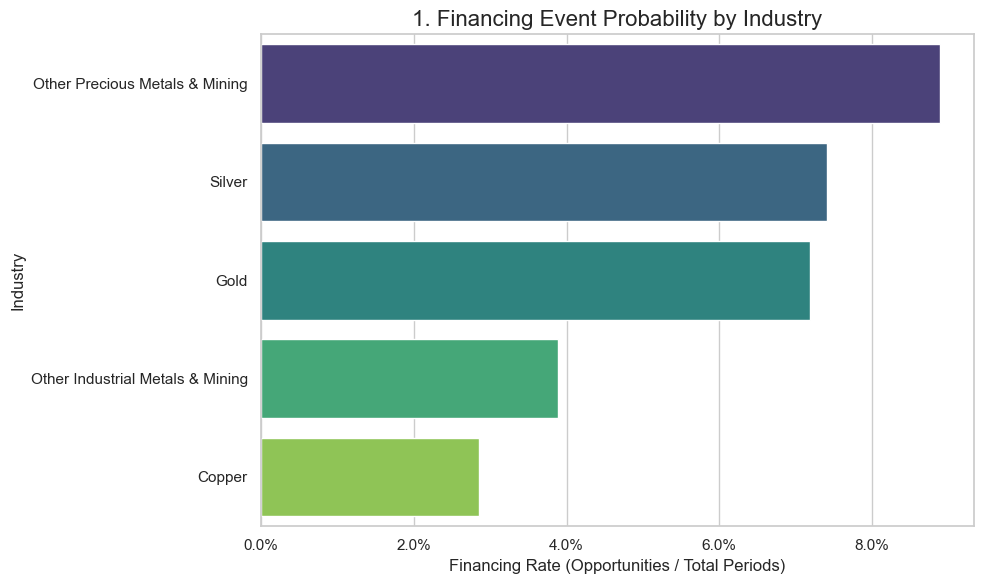

In [8]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. PySpark Aggregation: Calculate Financing Rate per Industry ---
industry_agg = (
    df.groupBy("industry") 
    .agg(
        # Count the total number of periods observed for each industry
        F.count(F.lit(1)).alias("total_periods"),
        # Sum the total number of financing events in each industry
        F.sum("financing_next_period").alias("financing_count")
    )
    .withColumn(
        # Calculate the rate: total financings / total periods
        "financing_rate", 
        (F.col("financing_count") / F.col("total_periods"))
    )
    # Order descending to show the highest opportunities first
    .orderBy(F.desc("financing_rate"))
)

# --- 2. PySpark -> Pandas Collection ---
# Convert the result to a Pandas DataFrame for plotting
industry_pd = industry_agg.toPandas()

# --- 3. Pandas Visualization (Seaborn/Matplotlib) ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x="financing_rate", 
    y="industry", 
    data=industry_pd, 
    palette="viridis"
)

# Formatting X-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.1%}'.format(x)))
plt.title('1. Financing Event Probability by Industry', fontsize=16)
plt.xlabel('Financing Rate (Opportunities / Total Periods)', fontsize=12)
plt.ylabel('Industry', fontsize=12)
plt.tight_layout()
plt.show()

this chart above measures the total periods as the only periods for which we have data for that industry in our basetable

**Empirical Financing Rate: A Hazard Rate Approach** The **Financing Rate** is calculated as the total number of financing events (`financing_count`) divided by the total number of observed bi-weekly windows (`total_periods`). We utilize this **Relative Rate** instead of absolute counts to ensure a fair comparison across sectors, effectively normalizing for industry size and company lifespan to identify true **Risk Density**. This metric represents the **Empirical Probability** (or Hazard Rate) of a dilution event occurring in any single 2-week window; for instance, a rate of 0.05 implies a 5% likelihood of a capital raise per period. Ultimately, this serves as our **Base Rate**—the statistical hurdle that our machine learning model must outperform to demonstrate predictive "Alpha."

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\3876695539.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


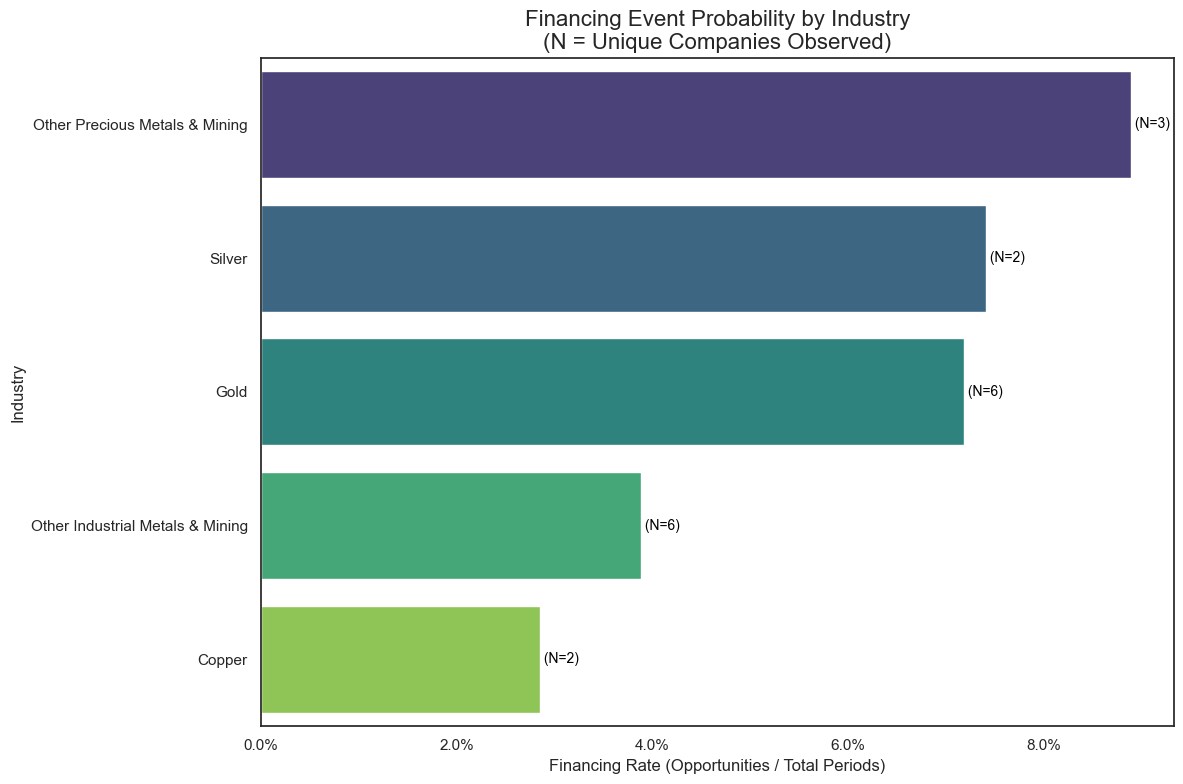

In [11]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Gebruik 'ticker' als unieke identifier voor bedrijven om de foutmelding te voorkomen
company_col = "ticker" 

# --- 1. PySpark Aggregation ---
industry_agg = (
    df.groupBy("industry") 
    .agg(
        F.count(F.lit(1)).alias("total_periods"),
        F.sum("financing_next_period").alias("financing_count"),
        F.countDistinct(company_col).alias("unique_companies")
    )
    .withColumn(
        "financing_rate", 
        (F.col("financing_count") / F.col("total_periods"))
    )
    .orderBy(F.desc("financing_rate"))
)

# --- 2. PySpark -> Pandas ---
industry_pd = industry_agg.toPandas()

# --- 3. Pandas Visualization ---
sns.set_theme(style="white")
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x="financing_rate", 
    y="industry", 
    data=industry_pd, 
    palette="viridis"
)

# --- 4. Annotaties toevoegen ---
for i, row in industry_pd.iterrows():
    rate = row['financing_rate']
    count = row['unique_companies']
    label_text = f" (N={count})"
    
    plt.text(
        x=rate, 
        y=i, 
        s=label_text, 
        color='black',
        va='center', 
        fontsize=10,
        fontweight='light'
    )

# Formattering
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.1%}'.format(x)))
plt.title('Financing Event Probability by Industry\n(N = Unique Companies Observed)', fontsize=16)
plt.xlabel('Financing Rate (Opportunities / Total Periods)', fontsize=12)
plt.ylabel('Industry', fontsize=12)

plt.tight_layout()
plt.show()

This code is specifically for Renzo

now aggregation per maturity level 

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\2008270888.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


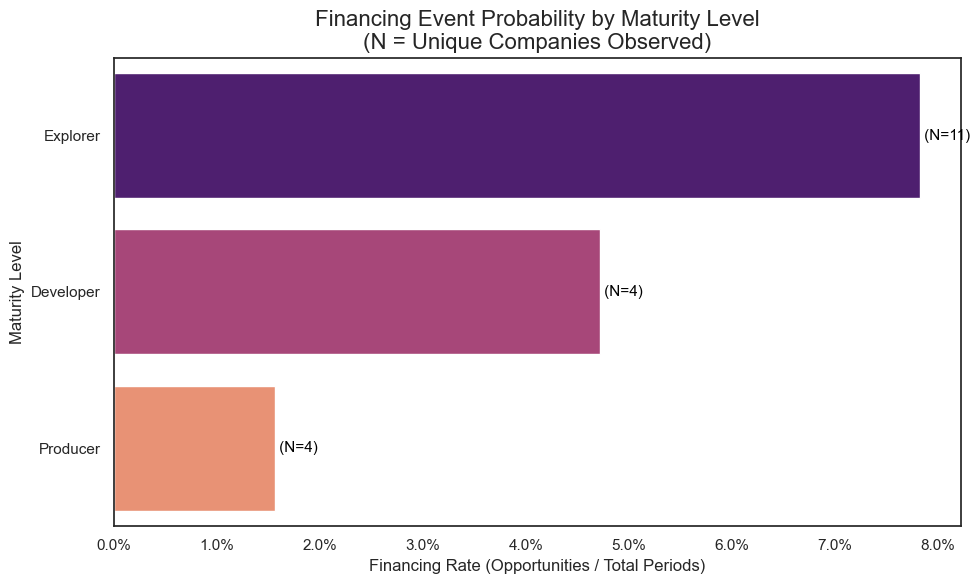

In [12]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Use 'ticker' as the unique identifier for companies
company_col = "ticker" 

# --- 1. PySpark Aggregation ---
# Group by 'maturity' to analyze financing risk per stage
maturity_agg = (
    df.groupBy("maturity") 
    .agg(
        # 1. Total number of observed periods (bi-weeks) per stage
        F.count(F.lit(1)).alias("total_periods"),
        # 2. Total number of financing events per stage
        F.sum("financing_next_period").alias("financing_count"),
        # 3. Number of unique companies per stage
        F.countDistinct(company_col).alias("unique_companies")
    )
    .withColumn(
        # Calculate the empirical probability: Events / Opportunities
        "financing_rate", 
        (F.col("financing_count") / F.col("total_periods"))
    )
    # Sort by the highest risk rate
    .orderBy(F.desc("financing_rate"))
)

# --- 2. PySpark -> Pandas Conversion ---
# Move the aggregated data to the driver for plotting
maturity_pd = maturity_agg.toPandas()

# --- 3. Pandas Visualization ---
sns.set_theme(style="white")
plt.figure(figsize=(10, 6))

# Use the 'magma' palette for a distinct visual style
ax = sns.barplot(
    x="financing_rate", 
    y="maturity", 
    data=maturity_pd, 
    palette="magma"
)

# --- 4. Add Annotations (N = Number of unique companies) ---
# This adds context regarding the sample size for each bar
for i, row in maturity_pd.iterrows():
    rate = row['financing_rate']
    count = row['unique_companies']
    label_text = f" (N={count})"
    
    plt.text(
        x=rate, 
        y=i, 
        s=label_text, 
        color='black',
        va='center', 
        fontsize=11,
        fontweight='light'
    )

# Formatting the axes and title
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.1%}'.format(x)))
plt.title('Financing Event Probability by Maturity Level\n(N = Unique Companies Observed)', fontsize=16)
plt.xlabel('Financing Rate (Opportunities / Total Periods)', fontsize=12)
plt.ylabel('Maturity Level', fontsize=12)

plt.tight_layout()

# --- 5. SAVE THE PLOT ---
# Saving with high resolution (300 DPI) for the presentation
#plt.savefig('plot_for_renzo_maturity.png', dpi=300) 

# print("[INFO] The plot has been saved as 'plot_for_renzo_maturity.png'")

# Display the final result
plt.show()

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\1543513303.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


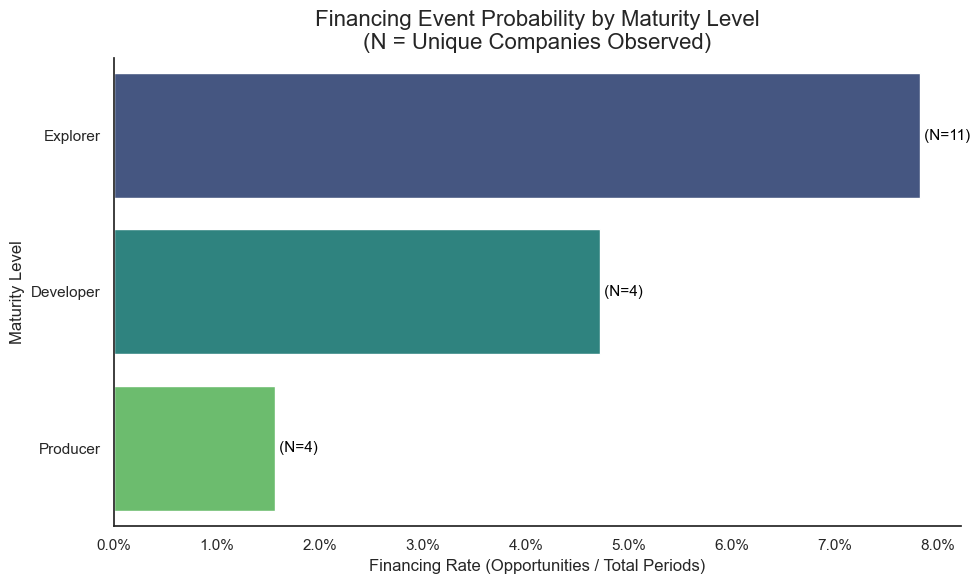

In [13]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Use 'ticker' as the unique identifier for companies
company_col = "ticker" 

# --- 1. PySpark Aggregation ---
# Group by 'maturity' to analyze financing risk per stage
maturity_agg = (
    df.groupBy("maturity") 
    .agg(
        # 1. Total number of observed periods (bi-weeks) per stage
        F.count(F.lit(1)).alias("total_periods"),
        # 2. Total number of financing events per stage
        F.sum("financing_next_period").alias("financing_count"),
        # 3. Number of unique companies per stage
        F.countDistinct(company_col).alias("unique_companies")
    )
    .withColumn(
        # Calculate the empirical probability: Events / Opportunities
        "financing_rate", 
        (F.col("financing_count") / F.col("total_periods"))
    )
    # Sort by the highest risk rate
    .orderBy(F.desc("financing_rate"))
)

# --- 2. PySpark -> Pandas Conversion ---
maturity_pd = maturity_agg.toPandas()

# --- 3. Pandas Visualization ---
# Using 'white' style to remove the background grid for a clean look
sns.set_theme(style="white")
plt.figure(figsize=(10, 6))

# Switched palette to 'viridis' to match the industry plot
ax = sns.barplot(
    x="financing_rate", 
    y="maturity", 
    data=maturity_pd, 
    palette="viridis"
)

# Ensure grid is off and remove top/right borders
ax.grid(False)
sns.despine()

# --- 4. Add Annotations (N = Number of unique companies) ---
for i, row in maturity_pd.iterrows():
    rate = row['financing_rate']
    count = row['unique_companies']
    label_text = f" (N={count})"
    
    plt.text(
        x=rate, 
        y=i, 
        s=label_text, 
        color='black',
        va='center', 
        fontsize=11,
        fontweight='light'
    )

# Formatting the axes and title
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.1%}'.format(x)))
plt.title('Financing Event Probability by Maturity Level\n(N = Unique Companies Observed)', fontsize=16)
plt.xlabel('Financing Rate (Opportunities / Total Periods)', fontsize=12)
plt.ylabel('Maturity Level', fontsize=12)

plt.tight_layout()

# --- 5. SAVE THE PLOT ---
# plt.savefig('plot_for_renzo_maturity_consistent.png', dpi=300) 

# print("[INFO] The plot has been saved as 'plot_for_renzo_maturity_consistent.png'")

plt.show()

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\3993505027.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


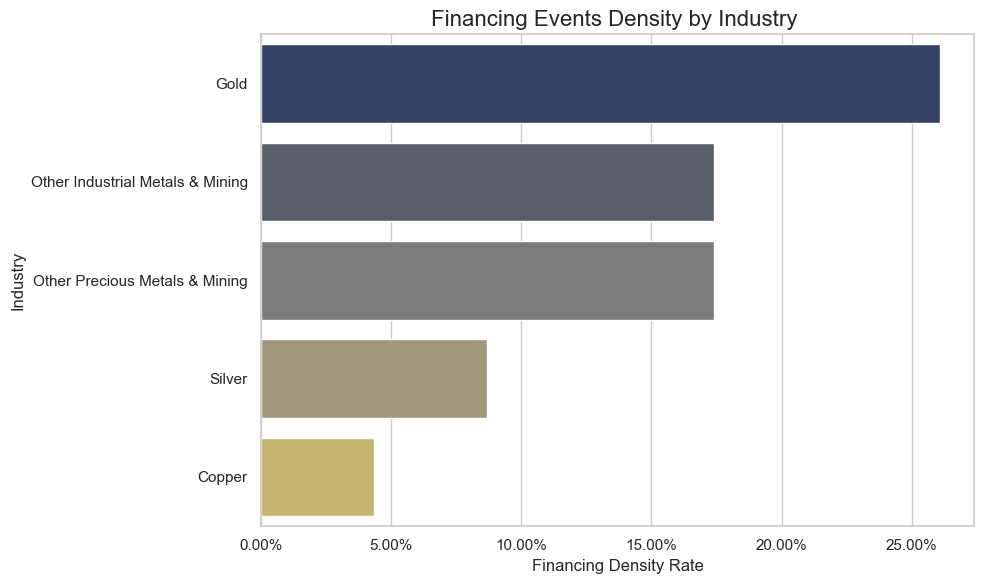

In [14]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- CONFIGURATION: Fixed Denominator ---
# The user specified 46 as the total number of biweekly periods in the dataset.
MAX_BIWEEKLY_PERIODS = 46.0 

# --- 1. PySpark Aggregation: Calculate Financing Rate per Industry (FIXED DENOMINATOR) ---
industry_agg_fixed = (
    df.groupBy("industry") 
    .agg(
        # Sum the total number of financing events in each industry
        F.sum("financing_next_period").alias("financing_count")
    )
    .withColumn(
        # Calculate the rate: total financings / FIXED max periods (46.0)
        "financing_rate_fixed", 
        (F.col("financing_count") / F.lit(MAX_BIWEEKLY_PERIODS))
    )
    # Order descending to show the highest 'density' first
    .orderBy(F.desc("financing_rate_fixed"))
)

# --- 2. PySpark -> Pandas Collection ---
# Convert the result to a Pandas DataFrame for plotting
industry_pd_fixed = industry_agg_fixed.toPandas()

# --- 3. Pandas Visualization (Seaborn/Matplotlib) ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x="financing_rate_fixed", 
    y="industry", 
    data=industry_pd_fixed, 
    palette="cividis"
)

# Formatting X-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.2%}'.format(x)))
plt.title('Financing Events Density by Industry ', fontsize=16)
plt.xlabel('Financing Density Rate', fontsize=12)
plt.ylabel('Industry', fontsize=12)
plt.tight_layout()
plt.show()

Now we use the density rate which is just the number of announcements divided by the total number of biweekly periods (46)

Fixed Density Rate: A Volume-Based Approach Unlike the empirical probability (hazard rate) which measures risk per individual observation, the Fixed Density Rate utilizes a constant denominator (46 bi-weekly periods) to measure the absolute frequency of events across the entire dataset duration. This approach shifts the focus from "individual company risk" to "sector activity volume." By dividing the total financing count by a fixed timeframe, we identify the industries with the highest absolute density of financing opportunities. For management, this visualization is essential for identifying market scale; it highlights the sectors where financing events occur most frequently in absolute terms, regardless of how many individual companies were active at any given moment

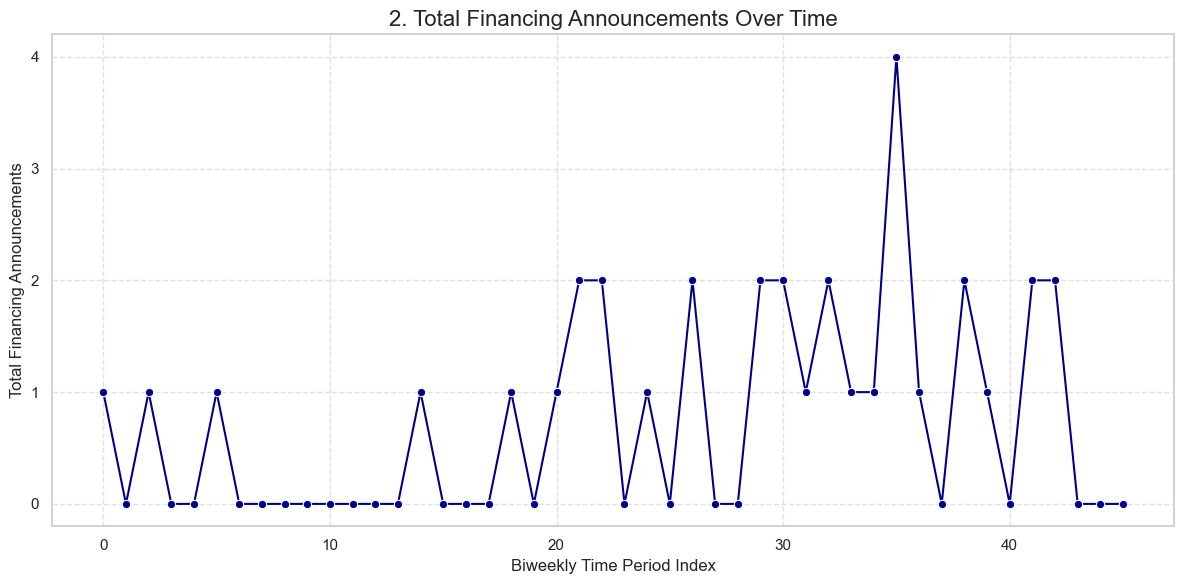

In [15]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker # Import the ticker module for axis formatting

# --- 1. PySpark Aggregation: Calculate Total Announcements per Period ---
time_agg = (
    df.groupBy("biweekly_index") 
    .agg(
        # Sum all financing events in each biweekly period
        F.sum("financing_next_period").alias("announcement_count")
    )
    # Ensure chronological order for plotting the time series
    .orderBy("biweekly_index")
)

# --- 2. PySpark -> Pandas Collection ---
time_pd = time_agg.toPandas()

# --- 3. Pandas Visualization (Matplotlib/Seaborn) ---
plt.figure(figsize=(12, 6))

# Assign the plot to 'ax' so we can manipulate the axes object
ax = sns.lineplot(
    x="biweekly_index", 
    y="announcement_count", 
    data=time_pd, 
    marker='o',
    color='darkblue'
)

# *** FIX: Force Y-axis Ticks to be Integers ***
# Use MultipleLocator to ensure ticks are only placed at whole numbers (1.0, 2.0, 3.0, etc.)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

# Formatting
plt.title('2. Total Financing Announcements Over Time', fontsize=16)
plt.xlabel('Biweekly Time Period Index', fontsize=12)
plt.ylabel('Total Financing Announcements', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

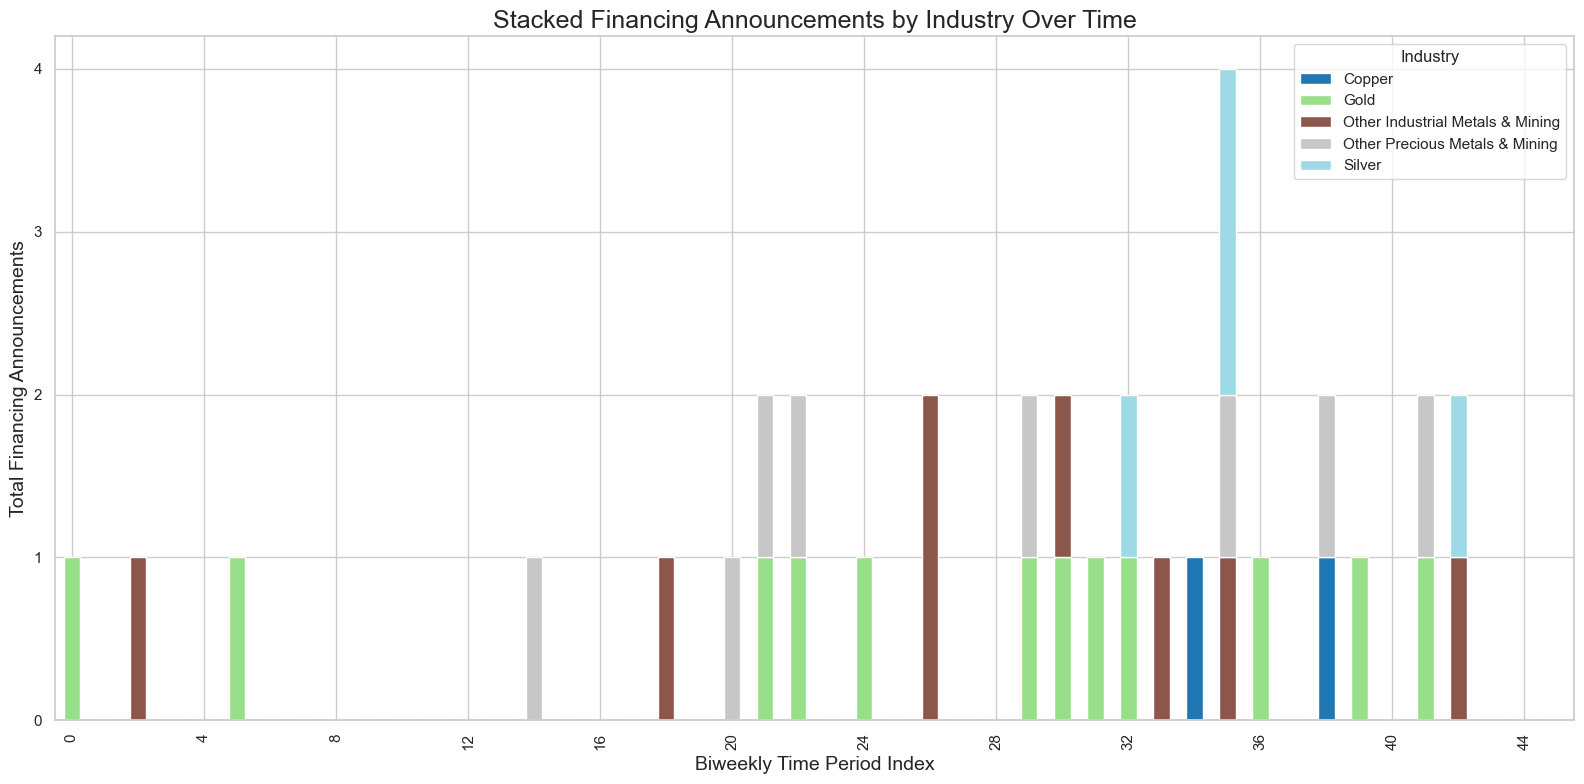

In [16]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker # Import the ticker module for axis formatting

# --- 1. PySpark Aggregation: Calculate Financing Count per BIWEEKLY PERIOD x INDUSTRY ---

stacked_agg = (
    df.groupBy("biweekly_index", "industry") 
    .agg(
        F.sum("financing_next_period").alias("announcement_count")
    )
    .orderBy("biweekly_index", "industry") 
)

# --- 2. PySpark -> Pandas Collection ---
stacked_pd = stacked_agg.toPandas()

# --- 3. Visualization (Stacked Bar Chart) ---

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 8))

# Prepare the data for stacking (pivoting from long to wide format)
pivot_df = stacked_pd.pivot_table(
    index='biweekly_index', 
    columns='industry', 
    values='announcement_count', 
    fill_value=0 
)

# Create the stacked bar plot
ax = pivot_df.plot(
    kind='bar', 
    stacked=True, 
    figsize=(16, 8), 
    colormap='tab20',
    ax=plt.gca() # Use the current figure/axes
)

# *** FIX: Force Y-axis Ticks to be Integers ***
# Use the MultipleLocator to ensure ticks are only placed at whole numbers (1.0, 2.0, 3.0, etc.)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

# Formatting
plt.title('Stacked Financing Announcements by Industry Over Time', fontsize=18)
plt.xlabel('Biweekly Time Period Index', fontsize=14)
plt.ylabel('Total Financing Announcements', fontsize=14)
plt.legend(title='Industry', loc='upper right')

# Optional: Adjust x-axis ticks to be less cluttered
num_ticks = 10
ax.set_xticks(ax.get_xticks()[::len(ax.get_xticks())//num_ticks])

plt.tight_layout()
plt.show()

A graph to visualize when did which anouncement happen

This plot directly quantifies the expected market impact of the event, justifying the urgency of detecting it early.

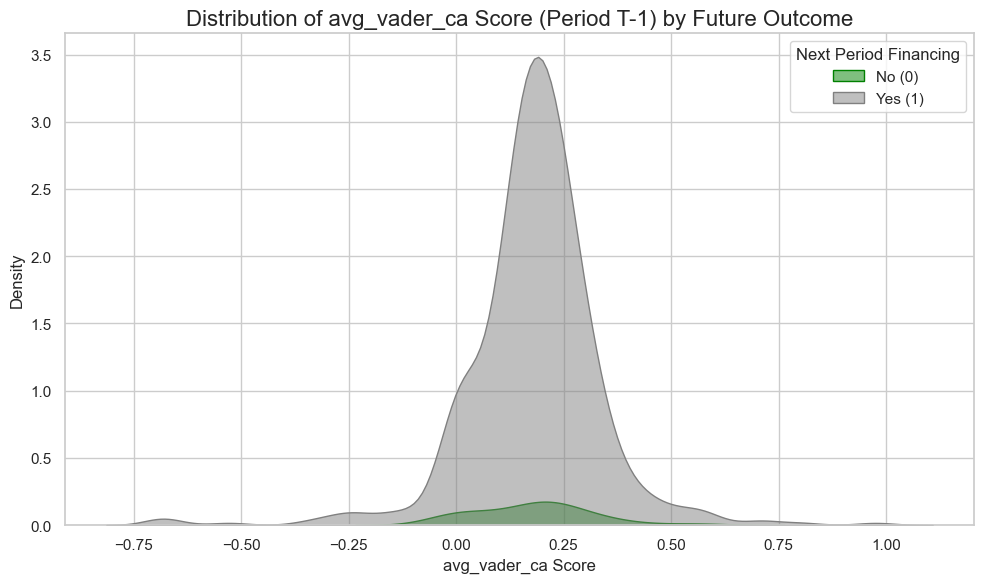

In [17]:
import pyspark.sql.functions as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SENTIMENT_FEATURE = "avg_vader_ca" # Replace with your best sentiment feature

# --- 1. PySpark Aggregation: Sample Data for Distribution Plot ---

# Select only the target and the sentiment feature
sentiment_plot_df = df.select(
    F.col("financing_next_period").alias("Target"),
    F.col(SENTIMENT_FEATURE).alias("Sentiment_Score")
).toPandas() # Collect full column for density plot

# --- 2. Visualization (Kernel Density Estimate Plot) ---
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=sentiment_plot_df, 
    x='Sentiment_Score', 
    hue='Target', 
    fill=True, 
    alpha=0.5,
    palette={0: 'gray', 1: 'green'}
)

# Formatting
plt.title(f'Distribution of {SENTIMENT_FEATURE} Score (Period T-1) by Future Outcome', fontsize=16)
plt.xlabel(f'{SENTIMENT_FEATURE} Score', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Next Period Financing', labels=['No (0)', 'Yes (1)'])

plt.tight_layout()
plt.show()

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\910709441.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Financing', y=metric, ax=ax,
C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\910709441.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Financing', y=metric, ax=ax,
C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\910709441.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Financing', y=metric, ax=ax,
C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\9107

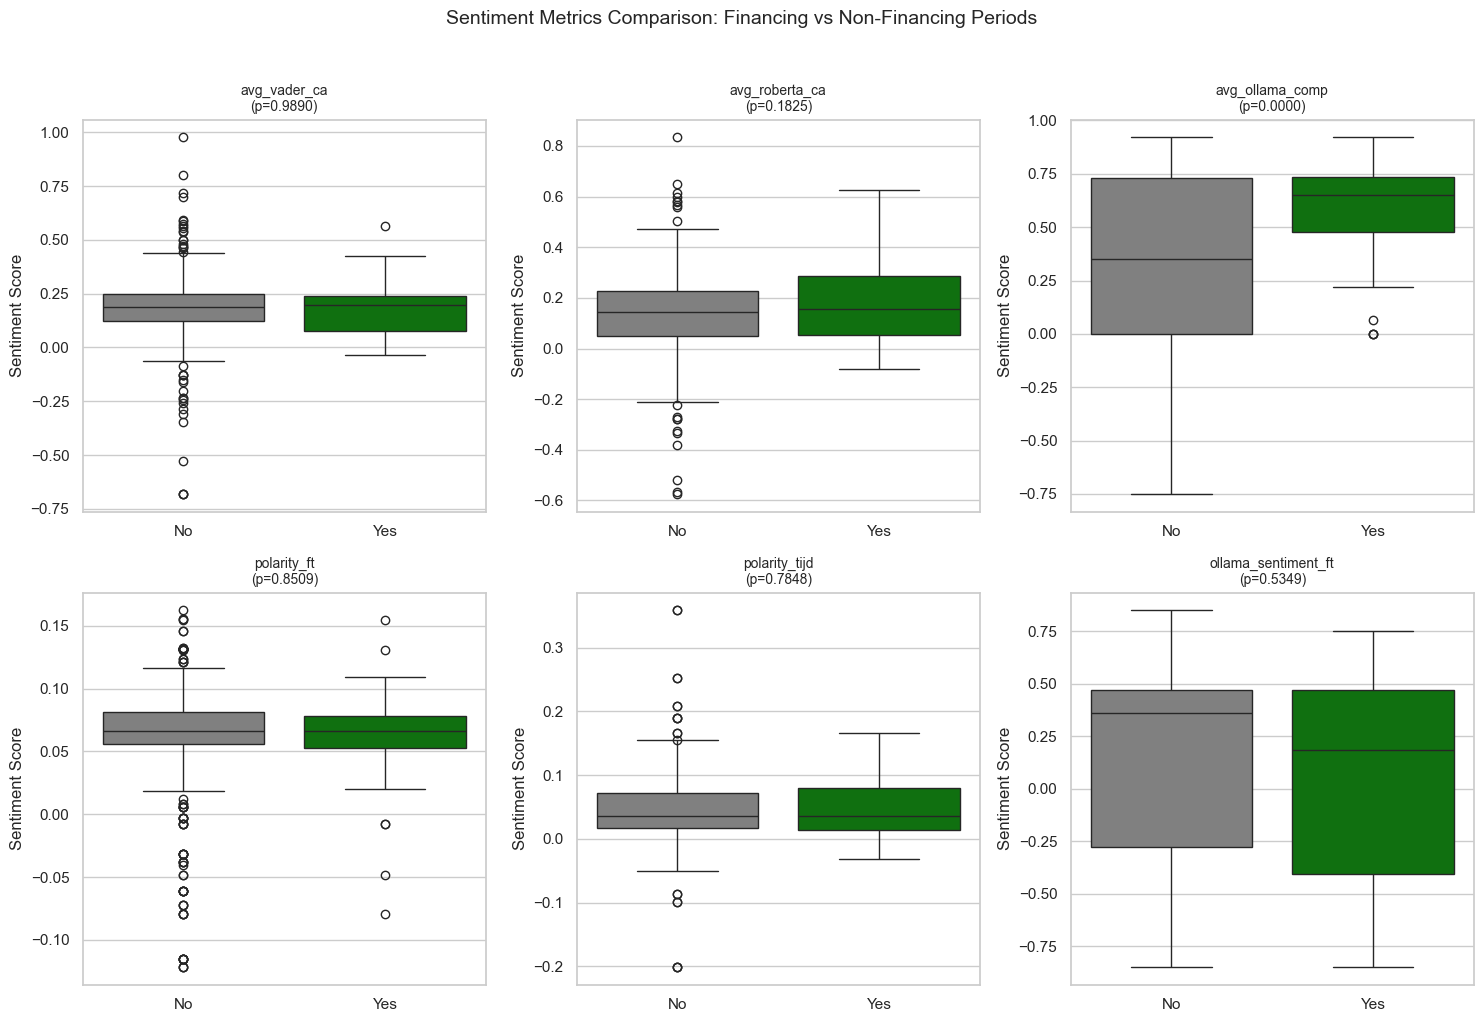

In [18]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Convert to pandas if not already
if isinstance(df, pd.DataFrame):
    plot_df = df
else:
    plot_df = df.toPandas()

# Convert financing_next_period to categorical for better visualization
plot_df['Financing'] = plot_df['financing_next_period'].map({0: 'No', 1: 'Yes'})

# 1A: Sentiment scores comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Sentiment metrics to analyze
sentiment_metrics = ['avg_vader_ca', 'avg_roberta_ca', 'avg_ollama_comp', 
                     'polarity_ft', 'polarity_tijd', 'ollama_sentiment_ft']

for idx, metric in enumerate(sentiment_metrics):
    ax = axes[idx // 3, idx % 3]
    
    # Box plot
    sns.boxplot(data=plot_df, x='Financing', y=metric, ax=ax, 
                palette={'No': 'gray', 'Yes': 'green'})
    
    # Calculate and display p-value
    group1 = plot_df[plot_df['Financing'] == 'No'][metric].dropna()
    group2 = plot_df[plot_df['Financing'] == 'Yes'][metric].dropna()
    
    if len(group1) > 0 and len(group2) > 0:
        t_stat, p_value = stats.ttest_ind(group1, group2, equal_var=False)
        ax.set_title(f'{metric}\n(p={p_value:.4f})', fontsize=10)
    
    ax.set_xlabel('')
    ax.set_ylabel('Sentiment Score')

plt.suptitle('Sentiment Metrics Comparison: Financing vs Non-Financing Periods', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\3583777690.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['Financial Times', 'De Tijd'])
C:\Users\Beheerder\AppData\Local\Temp\ipykernel_15208\3583777690.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(['Financial Times', 'De Tijd'])


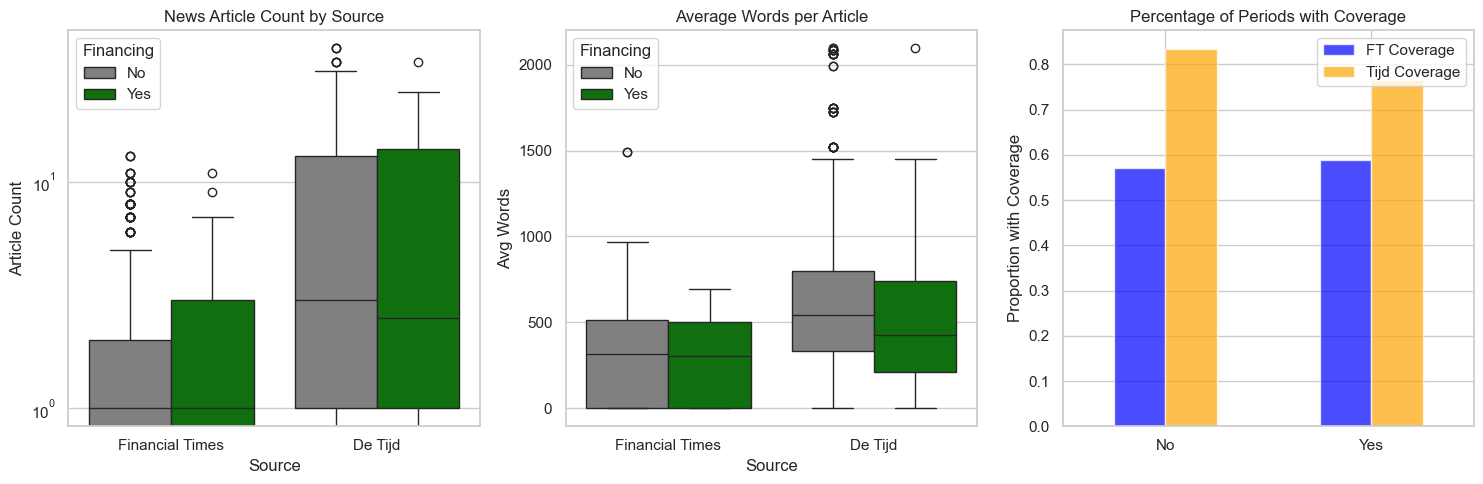

In [19]:
# 1C: News coverage analysis
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Article counts
ax1 = axes[0]
coverage_data = plot_df[['Financing', 'article_count_ft', 'article_count_tijd']].melt(
    id_vars=['Financing'], 
    var_name='Source', 
    value_name='Article Count'
)
sns.boxplot(data=coverage_data, x='Source', y='Article Count', hue='Financing', 
            ax=ax1, palette={'No': 'gray', 'Yes': 'green'})
ax1.set_title('News Article Count by Source')
ax1.set_xticklabels(['Financial Times', 'De Tijd'])
ax1.set_yscale('log')

# Words per article
ax2 = axes[1]
words_data = plot_df[['Financing', 'avg_words_ft', 'avg_words_tijd']].melt(
    id_vars=['Financing'], 
    var_name='Source', 
    value_name='Avg Words'
)
sns.boxplot(data=words_data, x='Source', y='Avg Words', hue='Financing', 
            ax=ax2, palette={'No': 'gray', 'Yes': 'green'})
ax2.set_title('Average Words per Article')
ax2.set_xticklabels(['Financial Times', 'De Tijd'])

# Coverage flags
ax3 = axes[2]
coverage_flags = plot_df.groupby('Financing')[['ft_coverage', 'tijd_coverage']].mean()
coverage_flags.plot(kind='bar', ax=ax3, color=['blue', 'orange'], alpha=0.7)
ax3.set_title('Percentage of Periods with Coverage')
ax3.set_ylabel('Proportion with Coverage')
ax3.set_xlabel('')
ax3.legend(['FT Coverage', 'Tijd Coverage'])
ax3.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Does not really tell us anything meaningfull

Now go more into detail for those which are worth pursuing

Analyzing Gold industry...


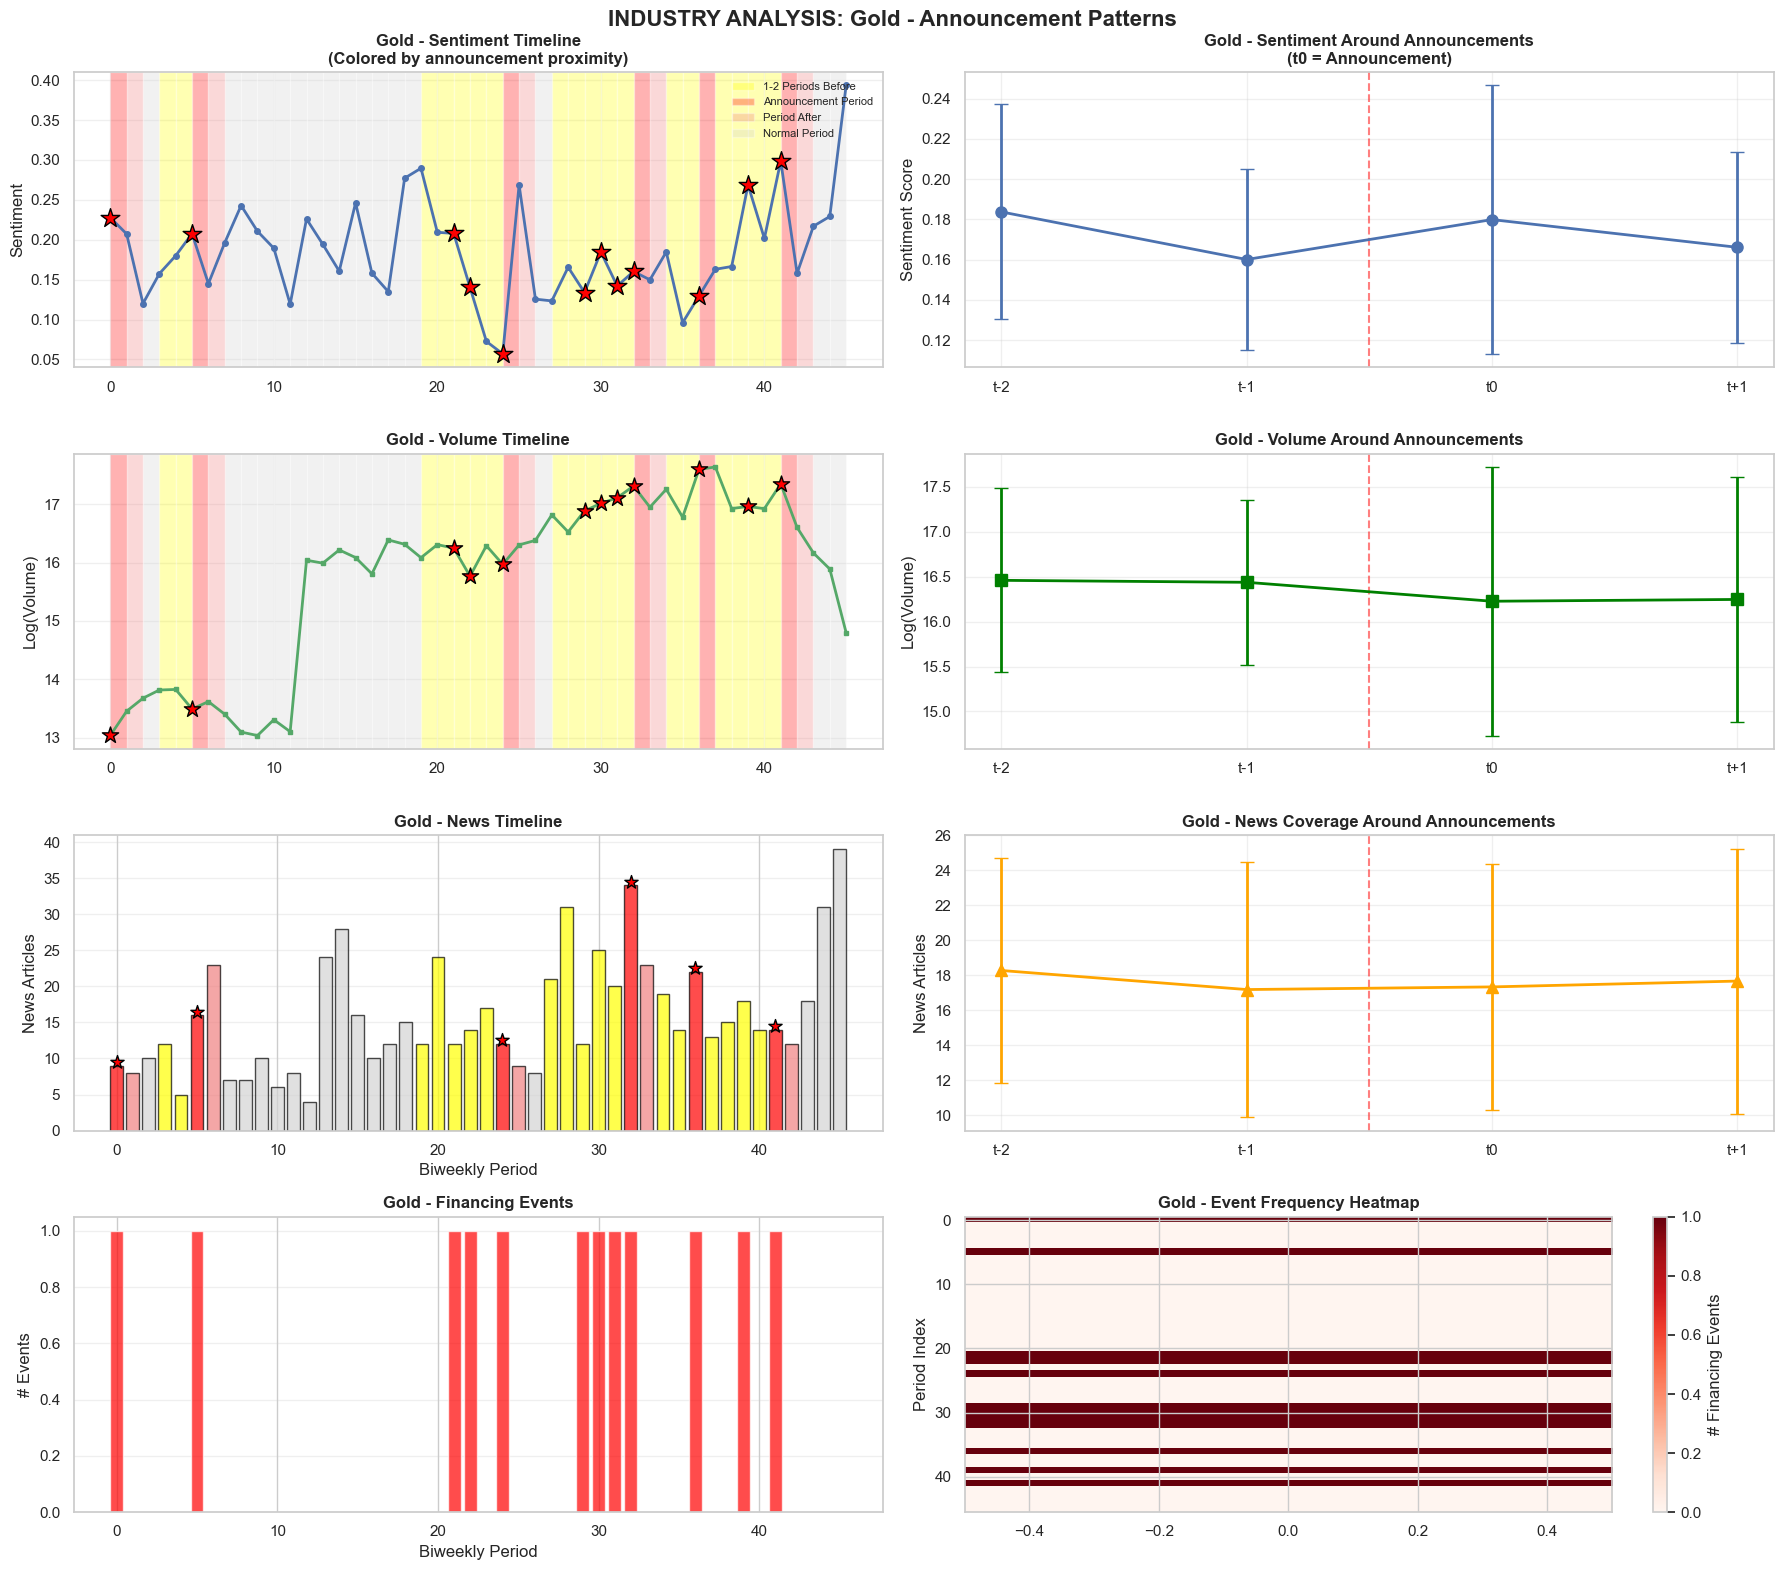


PATTERN ANALYSIS: Gold

Total Announcement Periods: 12
Total Financing Events: 12
Average events per announcement period: 1.00

Announcement Periods vs Non-Announcement Periods:
  Sentiment: 0.180 vs 0.188
  Volume: 19,605,772 vs 10,976,676
  News: 17.3 vs 15.4

Percentage Differences (Announcement vs Normal):
  Sentiment: -4.1%
  Volume: +78.6%
  News: +12.3%

Pattern Analysis (Window around announcements):
  Sentiment change before→at announcement: +4.7%
  Volume change before→at announcement: -1.3%
  News change before→at announcement: -2.2%

Analyzing Copper industry...


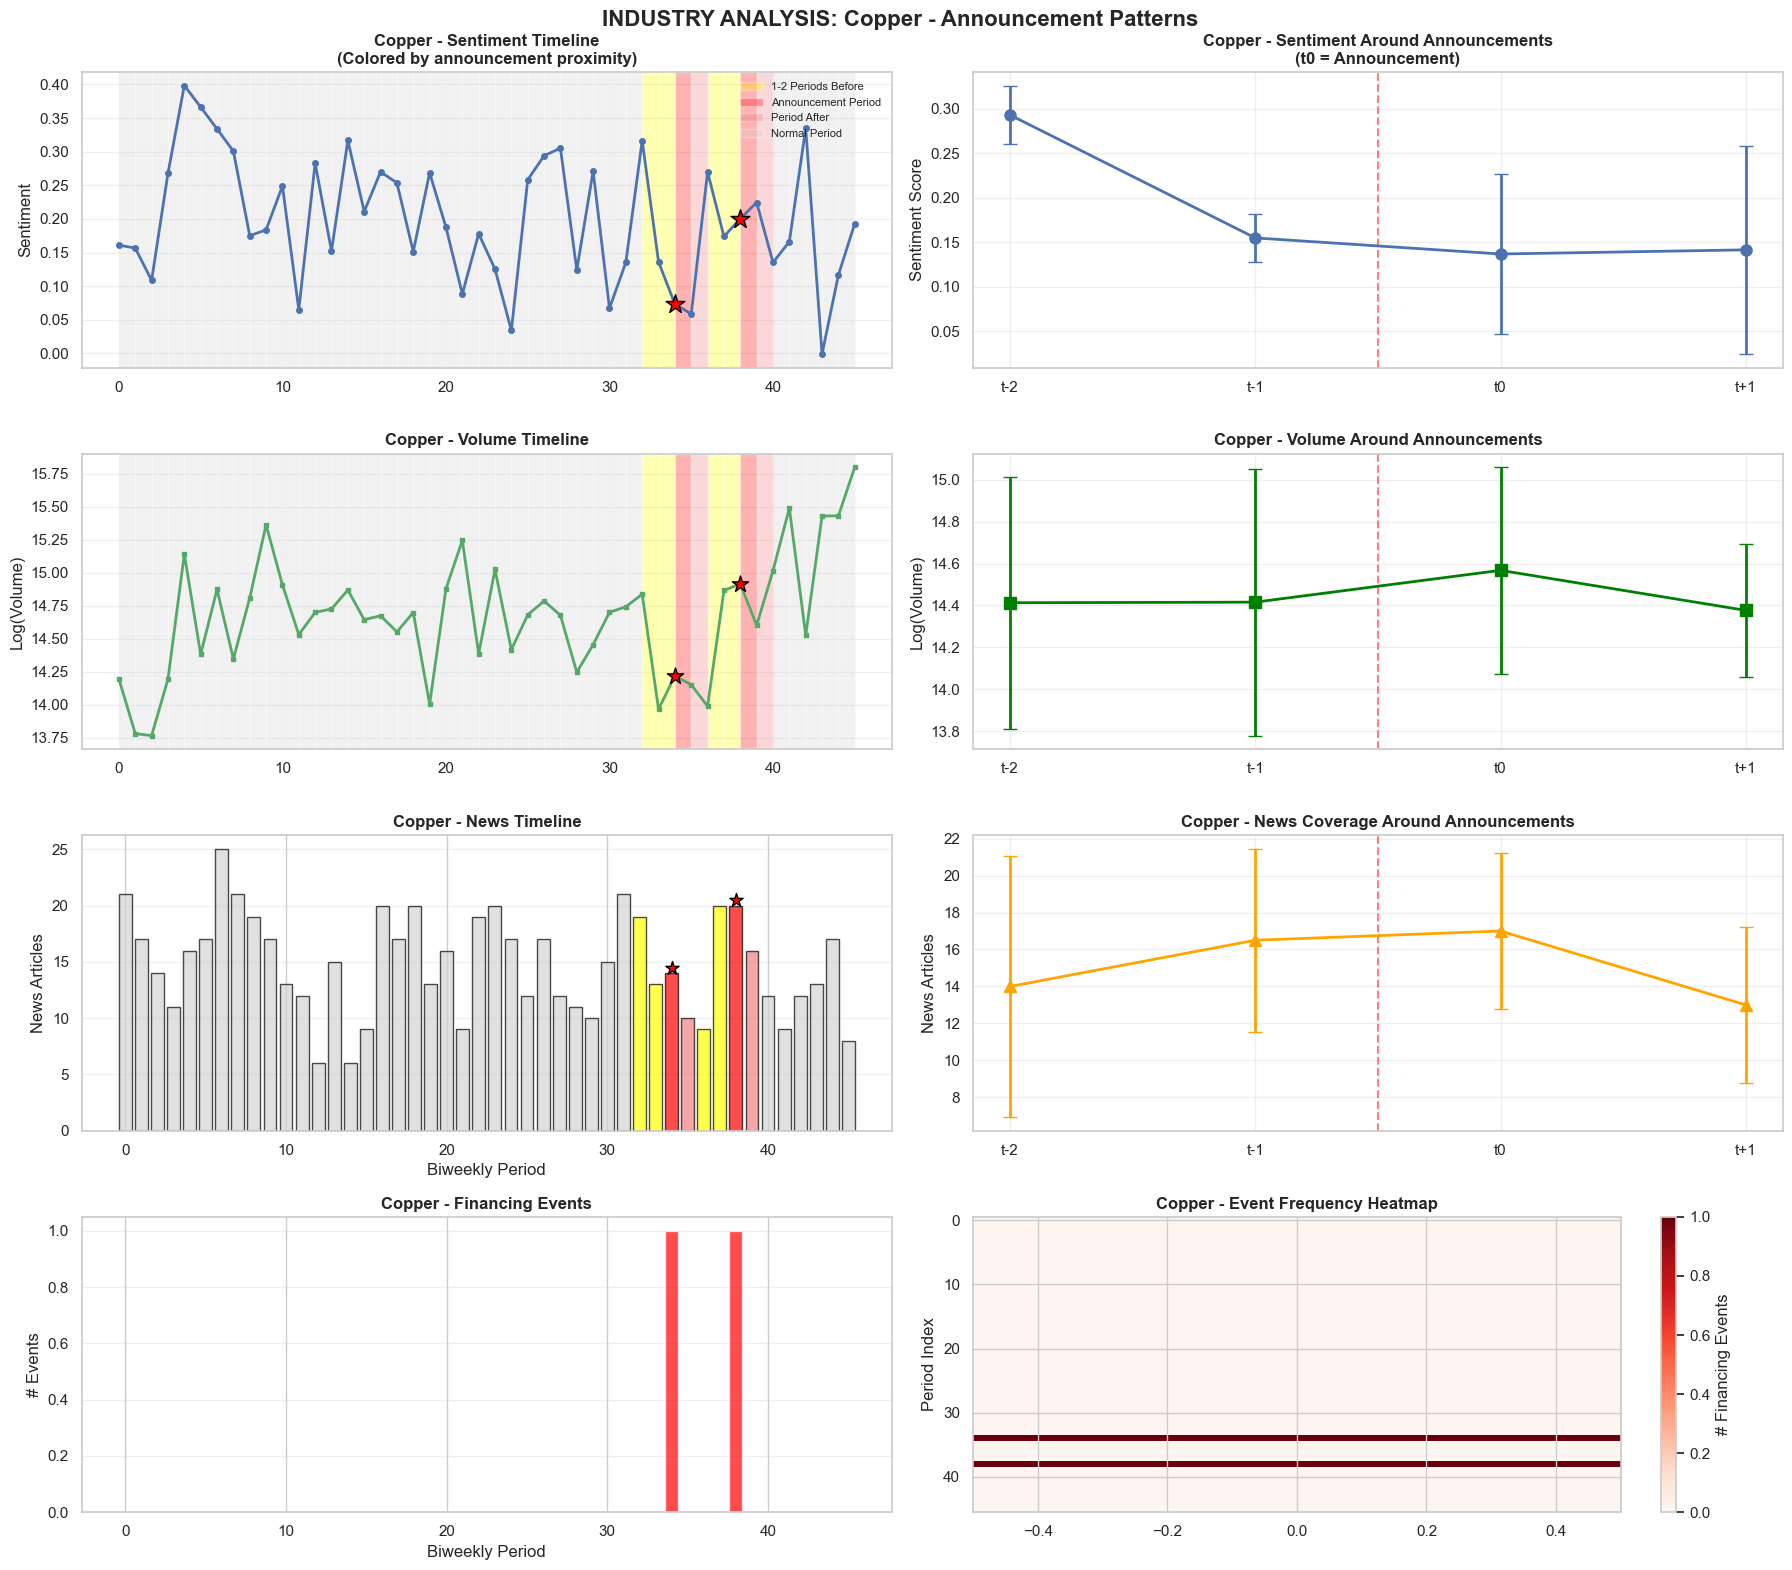


PATTERN ANALYSIS: Copper

Total Announcement Periods: 2
Total Financing Events: 2
Average events per announcement period: 1.00

Announcement Periods vs Non-Announcement Periods:
  Sentiment: 0.137 vs 0.202
  Volume: 2,251,075 vs 2,612,152
  News: 17.0 vs 14.7

Percentage Differences (Announcement vs Normal):
  Sentiment: -32.0%
  Volume: -13.8%
  News: +15.8%

Pattern Analysis (Window around announcements):
  Sentiment change before→at announcement: -38.9%
  Volume change before→at announcement: +1.1%
  News change before→at announcement: +11.5%


In [ ]:
def plot_industry_announcement_patterns(industry):
    """Plot showing industry patterns BEFORE and AFTER announcements"""
    
    industry_data = plot_df[plot_df['industry'] == industry].sort_values('biweekly_index')
    
    if len(industry_data) == 0:
        print(f"No data for industry: {industry}")
        return
    
    # Aggregate by period
    aggregated = industry_data.groupby('biweekly_index').agg({
        'avg_vader_ca': 'mean',
        'total_volume': 'mean',
        'article_count_tijd': 'mean',
        'financing_next_period': 'sum'
    }).reset_index()
    
    # Get announcement periods
    announcement_periods = aggregated[aggregated['financing_next_period'] > 0]['biweekly_index'].tolist()
    
    fig, axes = plt.subplots(4, 2, figsize=(18, 16))
    
    # Color coding for timeline
    colors = ['lightgray'] * len(aggregated)
    
    # Color periods around announcements
    for i, period in enumerate(aggregated['biweekly_index']):
        # Check if this period is near any announcement
        for ann in announcement_periods:
            if period == ann:  # Announcement period
                colors[i] = 'red'
            elif period in [ann-2, ann-1]:  # 1-2 periods before
                colors[i] = 'yellow'
            elif period == ann + 1:  # Period after
                colors[i] = 'lightcoral'
    
    # 1. TIMELINE WITH COLORED BACKGROUND
    ax1 = axes[0, 0]
    
    # Colored background
    for i in range(len(aggregated)-1):
        ax1.axvspan(aggregated['biweekly_index'].iloc[i], 
                   aggregated['biweekly_index'].iloc[i+1],
                   facecolor=colors[i], alpha=0.3)
    
    # Plot sentiment
    ax1.plot(aggregated['biweekly_index'], aggregated['avg_vader_ca'], 
            'b-', linewidth=2, marker='o', markersize=4)
    
    # Mark announcements
    for ann in announcement_periods:
        ann_data = aggregated[aggregated['biweekly_index'] == ann]
        if not ann_data.empty:
            ax1.scatter(ann, ann_data['avg_vader_ca'].iloc[0],
                       color='red', s=200, marker='*', edgecolor='black',
                       zorder=10)
    
    ax1.set_title(f'{industry} - Sentiment Timeline\n(Colored by announcement proximity)', 
                 fontsize=12, fontweight='bold')
    ax1.set_ylabel('Sentiment')
    ax1.grid(True, alpha=0.3)
    
    # 2. VOLUME TIMELINE
    ax2 = axes[1, 0]
    
    for i in range(len(aggregated)-1):
        ax2.axvspan(aggregated['biweekly_index'].iloc[i], 
                   aggregated['biweekly_index'].iloc[i+1],
                   facecolor=colors[i], alpha=0.3)
    
    ax2.plot(aggregated['biweekly_index'], np.log1p(aggregated['total_volume']),
            'g-', linewidth=2, marker='s', markersize=3)
    
    for ann in announcement_periods:
        ann_data = aggregated[aggregated['biweekly_index'] == ann]
        if not ann_data.empty:
            ax2.scatter(ann, np.log1p(ann_data['total_volume'].iloc[0]),
                       color='red', s=150, marker='*', edgecolor='black',
                       zorder=10)
    
    ax2.set_title(f'{industry} - Volume Timeline', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Log(Volume)')
    ax2.grid(True, alpha=0.3)
    
    # 3. NEWS TIMELINE
    ax3 = axes[2, 0]
    
    for i, (period, news_count) in enumerate(zip(aggregated['biweekly_index'], 
                                                aggregated['article_count_tijd'])):
        bar_color = colors[i]
        ax3.bar(period, news_count, color=bar_color, alpha=0.7, edgecolor='black')
        
        if bar_color == 'red':
            ax3.scatter(period, news_count + 0.5, color='red', s=100,
                       marker='*', edgecolor='black', zorder=5)
    
    ax3.set_title(f'{industry} - News Timeline', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Biweekly Period')
    ax3.set_ylabel('News Articles')
    ax3.grid(True, alpha=0.3, axis='y')
    
    # 4. FINANCING EVENTS
    ax4 = axes[3, 0]
    ax4.bar(aggregated['biweekly_index'], aggregated['financing_next_period'],
           color='red', alpha=0.7)
    ax4.set_title(f'{industry} - Financing Events', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Biweekly Period')
    ax4.set_ylabel('# Events')
    ax4.grid(True, alpha=0.3, axis='y')
    
    # 5. PRE/POST ANNOUNCEMENT ANALYSIS (RIGHT SIDE)
    
    # Analyze patterns around announcements
    if announcement_periods:
        # Create a DataFrame for pattern analysis - FIXED COLUMN NAMES
        pattern_data = []
        
        for ann in announcement_periods:
            # Get data for period window around announcement
            window_data = {}
            
            # Use different offset labels without special characters
            offsets = {
                -2: 't_minus_2',  # 2 periods before
                -1: 't_minus_1',  # 1 period before
                 0: 't_0',        # announcement period
                 1: 't_plus_1'    # 1 period after
            }
            
            for offset, label in offsets.items():
                period_idx = ann + offset
                period_data = aggregated[aggregated['biweekly_index'] == period_idx]
                
                if not period_data.empty:
                    window_data[f'sentiment_{label}'] = period_data['avg_vader_ca'].iloc[0]
                    window_data[f'volume_{label}'] = np.log1p(period_data['total_volume'].iloc[0])
                    window_data[f'news_{label}'] = period_data['article_count_tijd'].iloc[0]
                else:
                    window_data[f'sentiment_{label}'] = np.nan
                    window_data[f'volume_{label}'] = np.nan
                    window_data[f'news_{label}'] = np.nan
            
            pattern_data.append(window_data)
        
        pattern_df = pd.DataFrame(pattern_data)
        
        # Plot sentiment pattern
        ax5 = axes[0, 1]
        time_labels = ['t-2', 't-1', 't0', 't+1']
        sentiment_labels = ['sentiment_t_minus_2', 'sentiment_t_minus_1', 'sentiment_t_0', 'sentiment_t_plus_1']
        
        sentiment_means = [pattern_df[col].mean() for col in sentiment_labels]
        sentiment_stds = [pattern_df[col].std() for col in sentiment_labels]
        
        ax5.errorbar(time_labels, sentiment_means, yerr=sentiment_stds,
                    fmt='o-', capsize=5, linewidth=2, markersize=8)
        ax5.axvline(x=1.5, color='red', linestyle='--', alpha=0.5)  # Between t-1 and t0
        ax5.set_title(f'{industry} - Sentiment Around Announcements\n(t0 = Announcement)', 
                     fontsize=12, fontweight='bold')
        ax5.set_ylabel('Sentiment Score')
        ax5.grid(True, alpha=0.3)
        
        # Plot volume pattern
        ax6 = axes[1, 1]
        volume_labels = ['volume_t_minus_2', 'volume_t_minus_1', 'volume_t_0', 'volume_t_plus_1']
        
        volume_means = [pattern_df[col].mean() for col in volume_labels]
        volume_stds = [pattern_df[col].std() for col in volume_labels]
        
        ax6.errorbar(time_labels, volume_means, yerr=volume_stds,
                    fmt='s-', capsize=5, linewidth=2, markersize=8, color='green')
        ax6.axvline(x=1.5, color='red', linestyle='--', alpha=0.5)
        ax6.set_title(f'{industry} - Volume Around Announcements', fontsize=12, fontweight='bold')
        ax6.set_ylabel('Log(Volume)')
        ax6.grid(True, alpha=0.3)
        
        # Plot news pattern
        ax7 = axes[2, 1]
        news_labels = ['news_t_minus_2', 'news_t_minus_1', 'news_t_0', 'news_t_plus_1']
        
        news_means = [pattern_df[col].mean() for col in news_labels]
        news_stds = [pattern_df[col].std() for col in news_labels]
        
        ax7.errorbar(time_labels, news_means, yerr=news_stds,
                    fmt='^-', capsize=5, linewidth=2, markersize=8, color='orange')
        ax7.axvline(x=1.5, color='red', linestyle='--', alpha=0.5)
        ax7.set_title(f'{industry} - News Coverage Around Announcements', fontsize=12, fontweight='bold')
        ax7.set_ylabel('News Articles')
        ax7.grid(True, alpha=0.3)
        
        # Event frequency heatmap
        ax8 = axes[3, 1]
        # Count events by period position relative to biweekly index
        event_counts = aggregated.groupby('biweekly_index')['financing_next_period'].sum()
        heatmap_data = event_counts.values.reshape(-1, 1)  # Simple 1D heatmap
        
        im = ax8.imshow(heatmap_data, aspect='auto', cmap='Reds')
        ax8.set_title(f'{industry} - Event Frequency Heatmap', fontsize=12, fontweight='bold')
        ax8.set_xlabel('')
        ax8.set_ylabel('Period Index')
        plt.colorbar(im, ax=ax8, label='# Financing Events')
    
    # Add legend for colors
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='yellow', alpha=0.3, label='1-2 Periods Before'),
        Patch(facecolor='red', alpha=0.3, label='Announcement Period'),
        Patch(facecolor='lightcoral', alpha=0.3, label='Period After'),
        Patch(facecolor='lightgray', alpha=0.3, label='Normal Period')
    ]
    
    axes[0, 0].legend(handles=legend_elements, loc='upper right', fontsize=8)
    
    plt.suptitle(f'INDUSTRY ANALYSIS: {industry} - Announcement Patterns', 
                fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
    
    # Print statistical analysis
    print(f"\n{'='*70}")
    print(f"PATTERN ANALYSIS: {industry}")
    print('='*70)
    
    if announcement_periods:
        print(f"\nTotal Announcement Periods: {len(announcement_periods)}")
        total_events = aggregated['financing_next_period'].sum()
        print(f"Total Financing Events: {total_events}")
        print(f"Average events per announcement period: {aggregated[aggregated['financing_next_period'] > 0]['financing_next_period'].mean():.2f}")
        
        # Compare announcement vs non-announcement periods
        ann_periods = aggregated[aggregated['financing_next_period'] > 0]
        non_ann_periods = aggregated[aggregated['financing_next_period'] == 0]
        
        if len(ann_periods) > 0 and len(non_ann_periods) > 0:
            print(f"\nAnnouncement Periods vs Non-Announcement Periods:")
            print(f"  Sentiment: {ann_periods['avg_vader_ca'].mean():.3f} vs {non_ann_periods['avg_vader_ca'].mean():.3f}")
            print(f"  Volume: {ann_periods['total_volume'].mean():,.0f} vs {non_ann_periods['total_volume'].mean():,.0f}")
            print(f"  News: {ann_periods['article_count_tijd'].mean():.1f} vs {non_ann_periods['article_count_tijd'].mean():.1f}")
            
            # Calculate percentage differences
            if non_ann_periods['avg_vader_ca'].mean() != 0:
                sentiment_diff = ((ann_periods['avg_vader_ca'].mean() - non_ann_periods['avg_vader_ca'].mean()) / 
                                 abs(non_ann_periods['avg_vader_ca'].mean())) * 100
            else:
                sentiment_diff = 0
            
            if non_ann_periods['total_volume'].mean() != 0:
                volume_diff = ((ann_periods['total_volume'].mean() - non_ann_periods['total_volume'].mean()) / 
                              non_ann_periods['total_volume'].mean()) * 100
            else:
                volume_diff = 0
            
            if non_ann_periods['article_count_tijd'].mean() != 0:
                news_diff = ((ann_periods['article_count_tijd'].mean() - non_ann_periods['article_count_tijd'].mean()) / 
                            non_ann_periods['article_count_tijd'].mean()) * 100
            else:
                news_diff = 0
            
            print(f"\nPercentage Differences (Announcement vs Normal):")
            print(f"  Sentiment: {sentiment_diff:+.1f}%")
            print(f"  Volume: {volume_diff:+.1f}%")
            print(f"  News: {news_diff:+.1f}%")
            
            # Pattern analysis from window data
            if 'pattern_df' in locals() and len(pattern_df) > 0:
                print(f"\nPattern Analysis (Window around announcements):")
                
                # Calculate changes
                sentiment_before = pattern_df[['sentiment_t_minus_2', 'sentiment_t_minus_1']].mean().mean()
                sentiment_at = pattern_df['sentiment_t_0'].mean()
                sentiment_change = ((sentiment_at - sentiment_before) / abs(sentiment_before)) * 100 if sentiment_before != 0 else 0
                
                volume_before = pattern_df[['volume_t_minus_2', 'volume_t_minus_1']].mean().mean()
                volume_at = pattern_df['volume_t_0'].mean()
                volume_change = ((volume_at - volume_before) / abs(volume_before)) * 100 if volume_before != 0 else 0
                
                news_before = pattern_df[['news_t_minus_2', 'news_t_minus_1']].mean().mean()
                news_at = pattern_df['news_t_0'].mean()
                news_change = ((news_at - news_before) / abs(news_before)) * 100 if news_before != 0 else 0
                
                print(f"  Sentiment change before→at announcement: {sentiment_change:+.1f}%")
                print(f"  Volume change before→at announcement: {volume_change:+.1f}%")
                print(f"  News change before→at announcement: {news_change:+.1f}%")
    else:
        print("\nNo financing events found in this industry")

# Test for specific industries
print("Analyzing Gold industry...")
plot_industry_announcement_patterns('Gold')

print("\nAnalyzing Copper industry...")
plot_industry_announcement_patterns('Copper')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
import seaborn as sns
import os

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ============================================================================
# 1. CONVERT SPARK DATAFRAME TO PANDAS
# ============================================================================
print("Converting Spark DataFrame to pandas...")
df_pandas = df.toPandas()

# Show basic info
print(f"Data shape: {df_pandas.shape}")
print(f"Number of unique industries: {df_pandas['industry'].nunique()}")
print(f"Number of unique biweekly periods: {df_pandas['biweekly_period'].nunique()}")

# Show sample of biweekly_period values
print(f"\nSample biweekly_period values: {df_pandas['biweekly_period'].head(5).tolist()}")
print(f"Sample period_start values: {df_pandas['period_start'].head(3).tolist()}")

# ============================================================================
# 2. PREPARE THE DATA
# ============================================================================
# Convert period_start and period_end to datetime
df_pandas['period_start'] = pd.to_datetime(df_pandas['period_start'])
df_pandas['period_end'] = pd.to_datetime(df_pandas['period_end'])

# Create a proper period identifier using period_start
df_pandas['period_date'] = df_pandas['period_start']

# Sort by period for proper time series
df_pandas = df_pandas.sort_values(['industry', 'period_date'])

# Get unique industries
industries = sorted(df_pandas['industry'].unique().tolist())
print(f"\nIndustries found: {industries}")

# Get unique periods
periods = sorted(df_pandas['period_date'].unique())
print(f"Date range: {periods[0].strftime('%Y-%m-%d')} to {periods[-1].strftime('%Y-%m-%d')}")
print(f"Total periods: {len(periods)}")

# Create output directory
output_dir = 'industry_plots'
os.makedirs(output_dir, exist_ok=True)

# ============================================================================
# 3. AGGREGATE ARTICLE COUNTS PER INDUSTRY PER PERIOD - CORRECTED
# ============================================================================
print("\nAggregating article counts...")

# Create a summary DataFrame for article counts
article_summary = []

for industry in industries:
    industry_data = df_pandas[df_pandas['industry'] == industry]
    
    for period_date in periods:
        period_data = industry_data[industry_data['period_date'] == period_date]
        
        if len(period_data) > 0:
            # CORRECTED: Sum up all article counts with proper names
            ft_articles = period_data['article_count_ft'].sum()  # Financial Times
            tijd_articles = period_data['article_count_tijd'].sum()  # De Tijd
            company_articles = period_data['n_artices_comp'].sum()  # Company articles (NOT competitors)
            canada_articles = period_data['n_comments_ca'].sum() if 'n_comments_ca' in period_data.columns else 0  # Canadian articles
            
            # Total articles from all sources
            total_articles = ft_articles + tijd_articles + company_articles + canada_articles
            
            # Get the biweekly_period string for labeling
            biweekly_str = period_data['biweekly_period'].iloc[0] if 'biweekly_period' in period_data.columns else f"P{period_data['biweekly_index'].iloc[0] if 'biweekly_index' in period_data.columns else ''}"
            
            # Check for financing announcements - multiple indicators
            has_financing = False
            financing_indicators = []
            
            # Check all possible financing indicators
            if 'current_financing_announcement' in period_data.columns:
                if period_data['current_financing_announcement'].max() > 0:
                    has_financing = True
                    financing_indicators.append('current')
            
            if 'has_financing' in period_data.columns:
                if period_data['has_financing'].max() > 0 and not has_financing:
                    has_financing = True
                    financing_indicators.append('has_financing')
            
            if 'financing_next_period' in period_data.columns:
                if period_data['financing_next_period'].max() > 0:
                    # This is for NEXT period, but we might want to note it
                    financing_indicators.append('next_period')
            
            # Collect sentiment metrics if available
            sentiment_metrics = {}
            sentiment_cols = ['avg_polarity_content_comp', 'avg_subjectivity_content_comp', 
                             'avg_ollama_comp', 'avg_FPI_comp', 'polarity_tijd', 
                             'subjectivity_tijd', 'ollama_sentiment_tijd']
            
            for col in sentiment_cols:
                if col in period_data.columns:
                    sentiment_metrics[col] = period_data[col].mean()
            
            article_summary.append({
                'industry': industry,
                'period_date': period_date,
                'biweekly_label': biweekly_str,
                'biweekly_index': period_data['biweekly_index'].iloc[0] if 'biweekly_index' in period_data.columns else 0,
                # Article counts by source
                'ft_articles': ft_articles,  # Financial Times
                'tijd_articles': tijd_articles,  # De Tijd
                'company_articles': company_articles,  # Company articles
                'canada_articles': canada_articles,  # Canadian articles
                'total_articles': total_articles,
                # Financing info
                'has_financing': has_financing,
                'financing_indicators': ', '.join(financing_indicators) if financing_indicators else 'none',
                'financing_next_period': period_data['financing_next_period'].max() if 'financing_next_period' in period_data.columns else 0,
                # Add some key metrics
                'avg_close': period_data['avg_close'].mean() if 'avg_close' in period_data.columns else 0,
                'period_return': period_data['period_return'].mean() if 'period_return' in period_data.columns else 0,
                # Add sentiment metrics
                **sentiment_metrics
            })

df_articles = pd.DataFrame(article_summary)

print(f"Created article summary with {len(df_articles)} rows")
print(f"\nArticle sources breakdown:")
print(f"1. Financial Times (ft_articles)")
print(f"2. De Tijd (tijd_articles)")
print(f"3. Company articles (n_artices_comp)")
print(f"4. Canadian articles (n_comments_ca)")
print(f"\nSample data:\n{df_articles[['industry', 'period_date', 'total_articles', 'has_financing']].head()}")

# ============================================================================
# 4. CREATE INDIVIDUAL PLOTS FOR EACH INDUSTRY - WITH CORRECT LABELS
# ============================================================================
print("\n" + "="*80)
print("CREATING INDIVIDUAL INDUSTRY PLOTS")
print("="*80)

# Create color palette for industries
if len(industries) <= 10:
    colors = sns.color_palette("tab10", n_colors=len(industries))
else:
    colors = sns.color_palette("husl", n_colors=len(industries))

industry_colors = dict(zip(industries, colors))

# Source colors (corrected)
source_colors_corrected = {
    'ft_articles': '#1f77b4',  # Blue - Financial Times
    'tijd_articles': '#ff7f0e',  # Orange - De Tijd
    'company_articles': '#2ca02c',  # Green - Company articles
    'canada_articles': '#d62728'  # Red - Canadian articles
}

source_names_corrected = {
    'ft_articles': 'Financial Times',
    'tijd_articles': 'De Tijd',
    'company_articles': 'Company Articles',
    'canada_articles': 'Canadian Articles'
}

# Statistics collection
industry_stats = []

for idx, industry in enumerate(industries):
    print(f"\nProcessing {industry} ({idx+1}/{len(industries)})...")
    
    # Filter data for this industry
    industry_data = df_articles[df_articles['industry'] == industry].copy()
    
    # Ensure all periods are represented
    all_periods_df = pd.DataFrame({'period_date': periods})
    industry_data_full = pd.merge(all_periods_df, industry_data, 
                                 on='period_date', how='left')
    industry_data_full['industry'] = industry
    
    # Fill missing values
    for col in ['total_articles', 'ft_articles', 'tijd_articles', 'company_articles', 'canada_articles']:
        if col in industry_data_full.columns:
            industry_data_full[col] = industry_data_full[col].fillna(0)
    
    industry_data_full['has_financing'] = industry_data_full['has_financing'].fillna(False)
    
    # Sort by date
    industry_data_full = industry_data_full.sort_values('period_date')
    
    # Calculate statistics
    total_articles = industry_data_full['total_articles'].sum()
    avg_articles = industry_data_full['total_articles'].mean()
    max_articles = industry_data_full['total_articles'].max()
    financing_count = industry_data_full['has_financing'].sum()
    financing_pct = (financing_count / len(industry_data_full)) * 100
    
    # Calculate source breakdown
    ft_total = industry_data_full['ft_articles'].sum() if 'ft_articles' in industry_data_full.columns else 0
    tijd_total = industry_data_full['tijd_articles'].sum() if 'tijd_articles' in industry_data_full.columns else 0
    company_total = industry_data_full['company_articles'].sum() if 'company_articles' in industry_data_full.columns else 0
    canada_total = industry_data_full['canada_articles'].sum() if 'canada_articles' in industry_data_full.columns else 0
    
    industry_stats.append({
        'industry': industry,
        'total_articles': total_articles,
        'avg_articles_per_period': avg_articles,
        'max_articles_period': max_articles,
        'financing_count': financing_count,
        'financing_pct': financing_pct,
        'ft_articles': ft_total,
        'tijd_articles': tijd_total,
        'company_articles': company_total,
        'canada_articles': canada_total
    })
    
    # ========================================================================
    # PLOT 1: BAR CHART WITH FINANCING MARKERS (MAIN PLOT)
    # ========================================================================
    fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), 
                                    gridspec_kw={'height_ratios': [3, 1]},
                                    sharex=True)
    
    # Top panel: Article counts
    bars = ax1.bar(industry_data_full['period_date'], 
                   industry_data_full['total_articles'],
                   width=10,
                   color=industry_colors[industry],
                   alpha=0.8,
                   edgecolor='white',
                   linewidth=1.5,
                   label='Total Articles')
    
    # Add financing markers
    financing_periods = industry_data_full[industry_data_full['has_financing']]
    if not financing_periods.empty:
        for _, row in financing_periods.iterrows():
            # Position marker at top of bar
            y_pos = row['total_articles'] + (ax1.get_ylim()[1] * 0.02)
            
            ax1.scatter(row['period_date'], y_pos,
                       s=200,
                       c='gold',
                       edgecolor='black',
                       linewidth=2,
                       marker='*',
                       zorder=10)
            
            # Add annotation
            ax1.annotate('FINANCING',
                        xy=(row['period_date'], y_pos),
                        xytext=(0, 15),
                        textcoords='offset points',
                        ha='center',
                        va='bottom',
                        fontsize=9,
                        fontweight='bold',
                        color='darkred',
                        bbox=dict(boxstyle="round,pad=0.3", 
                                 facecolor='gold', 
                                 alpha=0.9,
                                 edgecolor='black'))
    
    # Format top panel
    ax1.set_ylabel('Number of Articles', fontsize=12, fontweight='bold')
    ax1.set_title(f'{industry} Industry: Article Volume & Financing Announcements', 
                  fontsize=14, fontweight='bold', pad=20)
    ax1.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax1.legend(['Articles', 'Financing Announcement'], loc='upper left')
    
    # Bottom panel: Financing indicator
    financing_indicator = industry_data_full['has_financing'].astype(int)
    ax2.bar(industry_data_full['period_date'], 
            financing_indicator,
            width=10,
            color=['lightgray' if not f else 'gold' for f in industry_data_full['has_financing']],
            edgecolor=['gray' if not f else 'black' for f in industry_data_full['has_financing']],
            linewidth=1)
    
    ax2.set_ylabel('Financing', fontsize=12, fontweight='bold')
    ax2.set_yticks([0, 1])
    ax2.set_yticklabels(['No', 'Yes'])
    ax2.set_ylim(-0.2, 1.2)
    
    # Format x-axis (shared)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=0, ha='center')
    ax2.set_xlabel('Period Start Date', fontsize=12, fontweight='bold')
    
    # Add statistics box with CORRECTED source breakdown
    stats_text = f"""Statistics for {industry}:
• Total Articles: {total_articles:,}
• Average per Period: {avg_articles:.1f}
• Maximum in Period: {max_articles:.0f}
• Financing Events: {financing_count}
• % Periods with Financing: {financing_pct:.1f}%

Article Sources:
• Financial Times: {ft_total:,} ({ft_total/total_articles*100:.1f}%)
• De Tijd: {tijd_total:,} ({tijd_total/total_articles*100:.1f}%)
• Company Articles: {company_total:,} ({company_total/total_articles*100:.1f}%)
• Canadian Articles: {canada_total:,} ({canada_total/total_articles*100:.1f}%)"""
    
    ax1.text(0.02, 0.98, stats_text, transform=ax1.transAxes,
            fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle="round,pad=0.5", 
                     facecolor='lightblue', 
                     alpha=0.8,
                     edgecolor='navy'))
    
    plt.tight_layout()
    
    # Save plot
    safe_industry_name = industry.replace(' ', '_').replace('/', '_').replace('\\', '_')
    fig1.savefig(f'{output_dir}/{safe_industry_name}_main.png', 
                 dpi=300, bbox_inches='tight')
    plt.close(fig1)
    
    print(f"  ✓ Created main plot: {safe_industry_name}_main.png")
    
    # ========================================================================
    # PLOT 2: STACKED AREA CHART BY SOURCE - CORRECTED
    # ========================================================================
    fig2, ax3 = plt.subplots(figsize=(16, 8))
    
    # Prepare data for stacked area with CORRECTED sources
    sources_corrected = ['ft_articles', 'tijd_articles', 'company_articles', 'canada_articles']
    
    # Fill missing values
    for source in sources_corrected:
        if source in industry_data_full.columns:
            industry_data_full[source] = industry_data_full[source].fillna(0)
    
    # Create stacked area
    bottom = np.zeros(len(industry_data_full))
    for source in sources_corrected:
        if source in industry_data_full.columns:
            values = industry_data_full[source].values
            ax3.fill_between(industry_data_full['period_date'], 
                            bottom, bottom + values,
                            color=source_colors_corrected[source], 
                            alpha=0.7, 
                            label=source_names_corrected[source])
            bottom += values
    
    # Add financing markers
    if not financing_periods.empty:
        for _, row in financing_periods.iterrows():
            ax3.scatter(row['period_date'], 
                       row['total_articles'] + (ax3.get_ylim()[1] * 0.02),
                       s=150, c='gold', edgecolor='black',
                       marker='*', zorder=10, label='Financing' if _ == financing_periods.index[0] else "")
    
    # Format
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax3.xaxis.get_majorticklabels(), rotation=0, ha='center')
    
    ax3.set_xlabel('Period Start Date', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Number of Articles', fontsize=12, fontweight='bold')
    ax3.set_title(f'{industry} Industry: Article Volume by Source', 
                  fontsize=14, fontweight='bold', pad=20)
    ax3.grid(True, alpha=0.3)
    ax3.legend(title='Article Source', loc='upper left', bbox_to_anchor=(1.02, 1))
    
    plt.tight_layout()
    fig2.savefig(f'{output_dir}/{safe_industry_name}_sources.png', 
                 dpi=300, bbox_inches='tight')
    plt.close(fig2)
    
    print(f"  ✓ Created sources plot: {safe_industry_name}_sources.png")
    
    # ========================================================================
    # PLOT 3: LINE PLOT SHOWING TRENDS
    # ========================================================================
    fig3, ax4 = plt.subplots(figsize=(16, 8))
    
    # Plot total articles line
    ax4.plot(industry_data_full['period_date'], 
             industry_data_full['total_articles'],
             color=industry_colors[industry], 
             linewidth=3,
             marker='o',
             markersize=6,
             label='Total Articles')
    
    # Plot individual sources as thinner lines
    if 'ft_articles' in industry_data_full.columns:
        ax4.plot(industry_data_full['period_date'], 
                 industry_data_full['ft_articles'],
                 color=source_colors_corrected['ft_articles'], 
                 linewidth=1.5,
                 linestyle='--',
                 alpha=0.7,
                 label='Financial Times')
    
    if 'tijd_articles' in industry_data_full.columns:
        ax4.plot(industry_data_full['period_date'], 
                 industry_data_full['tijd_articles'],
                 color=source_colors_corrected['tijd_articles'], 
                 linewidth=1.5,
                 linestyle='--',
                 alpha=0.7,
                 label='De Tijd')
    
    # Add financing markers as vertical lines
    if not financing_periods.empty:
        for _, row in financing_periods.iterrows():
            ax4.axvline(x=row['period_date'], color='red', 
                       alpha=0.5, linestyle=':', linewidth=2,
                       label='Financing' if _ == financing_periods.index[0] else "")
    
    # Format
    ax4.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax4.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax4.xaxis.get_majorticklabels(), rotation=0, ha='center')
    
    ax4.set_xlabel('Period Start Date', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Number of Articles', fontsize=12, fontweight='bold')
    ax4.set_title(f'{industry} Industry: Article Volume Trends', 
                  fontsize=14, fontweight='bold', pad=20)
    ax4.grid(True, alpha=0.3)
    ax4.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    
    plt.tight_layout()
    fig3.savefig(f'{output_dir}/{safe_industry_name}_trends.png', 
                 dpi=300, bbox_inches='tight')
    plt.close(fig3)
    
    print(f"  ✓ Created trends plot: {safe_industry_name}_trends.png")

# ============================================================================
# 5. CREATE INDUSTRY COMPARISON VISUALIZATIONS
# ============================================================================
print("\n" + "="*80)
print("CREATING INDUSTRY COMPARISON VISUALIZATIONS")
print("="*80)

# Convert stats to DataFrame
df_stats = pd.DataFrame(industry_stats).sort_values('total_articles', ascending=False)

# Plot 1: Industry comparison bar chart
fig4, ((ax5, ax6), (ax7, ax8)) = plt.subplots(2, 2, figsize=(20, 16))

# Total articles by industry
bars1 = ax5.barh(df_stats['industry'], df_stats['total_articles'],
                color=[industry_colors[ind] for ind in df_stats['industry']],
                alpha=0.8, edgecolor='black', linewidth=1)
ax5.set_xlabel('Total Articles', fontsize=12, fontweight='bold')
ax5.set_title('Total Article Volume by Industry', fontsize=14, fontweight='bold')
ax5.grid(True, alpha=0.3, axis='x')

# Add value labels
for bar in bars1:
    width = bar.get_width()
    ax5.text(width + width*0.01, bar.get_y() + bar.get_height()/2,
            f'{width:,.0f}', ha='left', va='center', fontweight='bold')

# Financing frequency by industry
bars2 = ax6.barh(df_stats['industry'], df_stats['financing_pct'],
                color=[industry_colors[ind] for ind in df_stats['industry']],
                alpha=0.8, edgecolor='black', linewidth=1)
ax6.set_xlabel('% of Periods with Financing', fontsize=12, fontweight='bold')
ax6.set_title('Financing Frequency by Industry', fontsize=14, fontweight='bold')
ax6.grid(True, alpha=0.3, axis='x')

# Add value labels
for bar in bars2:
    width = bar.get_width()
    ax6.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'{width:.1f}%', ha='left', va='center', fontweight='bold')

# Source breakdown - stacked bar
industries_plot = df_stats['industry'].head(10)  # Top 10 for clarity
source_totals = df_stats.set_index('industry')[['ft_articles', 'tijd_articles', 'company_articles', 'canada_articles']].head(10)

bottom = np.zeros(len(industries_plot))
for i, (source, color) in enumerate(zip(['ft_articles', 'tijd_articles', 'company_articles', 'canada_articles'], 
                                        ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])):
    values = source_totals[source].values
    ax7.barh(industries_plot, values, left=bottom, color=color, alpha=0.8, 
             edgecolor='black', linewidth=1, label=source_names_corrected[source])
    bottom += values

ax7.set_xlabel('Number of Articles', fontsize=12, fontweight='bold')
ax7.set_title('Article Source Breakdown by Industry (Top 10)', fontsize=14, fontweight='bold')
ax7.grid(True, alpha=0.3, axis='x')
ax7.legend(title='Article Source', loc='upper left', bbox_to_anchor=(1.02, 1))

# Average articles per period
ax8.barh(df_stats['industry'], df_stats['avg_articles_per_period'],
        color=[industry_colors[ind] for ind in df_stats['industry']],
        alpha=0.8, edgecolor='black', linewidth=1)
ax8.set_xlabel('Average Articles per Period', fontsize=12, fontweight='bold')
ax8.set_title('Average Article Volume by Industry', fontsize=14, fontweight='bold')
ax8.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
fig4.savefig(f'{output_dir}/industry_comparison.png', 
             dpi=300, bbox_inches='tight')
plt.close(fig4)
print("✓ Created: industry_comparison.png")

# ============================================================================
# 6. CREATE HEATMAP OF ARTICLE VOLUME
# ============================================================================
print("\nCreating heatmap...")

# Pivot for heatmap
heatmap_data = df_articles.pivot_table(
    index='industry',
    columns='period_date',
    values='total_articles',
    aggfunc='sum',
    fill_value=0
)

# Sort by total articles
industry_order = heatmap_data.sum(axis=1).sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[industry_order]

fig5, ax9 = plt.subplots(figsize=(20, max(8, len(industries)*0.5)))

# Create heatmap
im = ax9.imshow(heatmap_data.values, aspect='auto', cmap='YlOrRd', 
                interpolation='nearest', vmin=0)

# Add colorbar
cbar = plt.colorbar(im, ax=ax9, fraction=0.046, pad=0.04)
cbar.set_label('Number of Articles', fontsize=11, fontweight='bold')

# Set labels
ax9.set_yticks(np.arange(len(heatmap_data.index)))
ax9.set_yticklabels(heatmap_data.index, fontsize=10)
ax9.set_xticks(np.arange(len(heatmap_data.columns)))
ax9.set_xticklabels([d.strftime('%m/%d\n%Y') if i % 4 == 0 else '' 
                    for i, d in enumerate(heatmap_data.columns)], 
                   fontsize=8)

ax9.set_xlabel('Period Start Date', fontsize=12, fontweight='bold')
ax9.set_ylabel('Industry', fontsize=12, fontweight='bold')
ax9.set_title('Article Volume Heatmap by Industry and Period', 
              fontsize=14, fontweight='bold', pad=20)

# Add grid
ax9.set_xticks(np.arange(len(heatmap_data.columns)) - 0.5, minor=True)
ax9.set_yticks(np.arange(len(heatmap_data.index)) - 0.5, minor=True)
ax9.grid(which="minor", color="gray", linestyle='-', linewidth=0.5, alpha=0.3)
ax9.tick_params(which="minor", size=0)

plt.tight_layout()
fig5.savefig(f'{output_dir}/article_volume_heatmap.png', 
             dpi=300, bbox_inches='tight')
plt.close(fig5)
print("✓ Created: article_volume_heatmap.png")

# ============================================================================
# 7. CREATE SUMMARY REPORT
# ============================================================================
print("\n" + "="*80)
print("SUMMARY REPORT")
print("="*80)

# Create summary text file
with open(f'{output_dir}/summary_report.txt', 'w') as f:
    f.write("ARTICLE VOLUME AND FINANCING ANALYSIS REPORT\n")
    f.write("=" * 60 + "\n\n")
    
    f.write(f"Analysis Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Total Industries: {len(industries)}\n")
    f.write(f"Total Periods: {len(periods)}\n")
    f.write(f"Date Range: {periods[0].strftime('%Y-%m-%d')} to {periods[-1].strftime('%Y-%m-%d')}\n\n")
    
    f.write("ARTICLE SOURCES DEFINITION:\n")
    f.write("-" * 40 + "\n")
    f.write("1. Financial Times (article_count_ft): Articles from Financial Times\n")
    f.write("2. De Tijd (article_count_tijd): Articles from De Tijd newspaper\n")
    f.write("3. Company Articles (n_artices_comp): Articles about the specific company\n")
    f.write("4. Canadian Articles (n_comments_ca): Articles/comments from Canadian sources\n\n")
    
    f.write("INDUSTRY STATISTICS:\n")
    f.write("-" * 30 + "\n")
    
    for stat in industry_stats:
        f.write(f"\n{stat['industry']}:\n")
        f.write(f"  Total Articles: {stat['total_articles']:,}\n")
        f.write(f"  Average per Period: {stat['avg_articles_per_period']:.1f}\n")
        f.write(f"  Financing Events: {stat['financing_count']}\n")
        f.write(f"  % Periods with Financing: {stat['financing_pct']:.1f}%\n")
        f.write(f"  Source Breakdown:\n")
        f.write(f"    - Financial Times: {stat['ft_articles']:,} ({stat['ft_articles']/stat['total_articles']*100:.1f}%)\n")
        f.write(f"    - De Tijd: {stat['tijd_articles']:,} ({stat['tijd_articles']/stat['total_articles']*100:.1f}%)\n")
        f.write(f"    - Company Articles: {stat['company_articles']:,} ({stat['company_articles']/stat['total_articles']*100:.1f}%)\n")
        f.write(f"    - Canadian Articles: {stat['canada_articles']:,} ({stat['canada_articles']/stat['total_articles']*100:.1f}%)\n")
    
    f.write("\n\nTOP 5 INDUSTRIES BY ARTICLE VOLUME:\n")
    f.write("-" * 40 + "\n")
    top_5 = df_stats.head(5)
    for i, row in top_5.iterrows():
        f.write(f"{row['industry']}: {row['total_articles']:,} articles\n")
    
    f.write("\n\nFILES CREATED:\n")
    f.write("-" * 20 + "\n")
    
    # List created files
    import glob
    created_files = glob.glob(f'{output_dir}/*.png')
    for file in sorted(created_files):
        f.write(f"{os.path.basename(file)}\n")

print(f"\n✓ Analysis complete!")
print(f"✓ Created {len(industries)} industry plots")
print(f"✓ Created comparison visualizations")
print(f"✓ Created heatmap")
print(f"✓ Created summary report")
print(f"\nAll files saved to: {output_dir}/")
print(f"\nFor each industry, you'll find:")
print("  1. [industry]_main.png - Main article volume with financing markers")
print("  2. [industry]_sources.png - Stacked area by article source (CORRECTED)")
print("  3. [industry]_trends.png - Line plot showing trends")
print(f"\nPlus comparison files:")
print("  • industry_comparison.png - Industry rankings with source breakdown")
print("  • article_volume_heatmap.png - Heatmap view")
print("  • summary_report.txt - Detailed statistics with source definitions")

Converting Spark DataFrame to pandas...
Data shape: (587, 94)
Number of unique industries: 5
Number of unique biweekly periods: 46

Sample biweekly_period values: ['P0', 'P1', 'P2', 'P3', 'P4']
Sample period_start values: [datetime.date(2024, 1, 15), datetime.date(2024, 1, 29), datetime.date(2024, 2, 12)]

Industries found: ['Copper', 'Gold', 'Other Industrial Metals & Mining', 'Other Precious Metals & Mining', 'Silver']
Date range: 2024-01-15 to 2025-10-06
Total periods: 63

Aggregating article counts...
Created article summary with 222 rows

Article sources breakdown:
1. Financial Times (ft_articles)
2. De Tijd (tijd_articles)
3. Company articles (n_artices_comp)
4. Canadian articles (n_comments_ca)

Sample data:
  industry period_date  total_articles  has_financing
0   Copper  2024-01-15            28.0          False
1   Copper  2024-01-29            36.0          False
2   Copper  2024-02-12            29.0          False
3   Copper  2024-02-26            43.0          False
4   C

C:\Users\Beheerder\AppData\Local\Temp\ipykernel_11940\2568582166.py:193: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



  ✓ Created main plot: Copper_main.png
  ✓ Created sources plot: Copper_sources.png
  ✓ Created trends plot: Copper_trends.png

Processing Gold (2/5)...


C:\Users\Beheerder\AppData\Local\Temp\ipykernel_11940\2568582166.py:193: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



  ✓ Created main plot: Gold_main.png
  ✓ Created sources plot: Gold_sources.png
  ✓ Created trends plot: Gold_trends.png

Processing Other Industrial Metals & Mining (3/5)...


C:\Users\Beheerder\AppData\Local\Temp\ipykernel_11940\2568582166.py:193: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



  ✓ Created main plot: Other_Industrial_Metals_&_Mining_main.png
  ✓ Created sources plot: Other_Industrial_Metals_&_Mining_sources.png
  ✓ Created trends plot: Other_Industrial_Metals_&_Mining_trends.png

Processing Other Precious Metals & Mining (4/5)...


C:\Users\Beheerder\AppData\Local\Temp\ipykernel_11940\2568582166.py:193: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



  ✓ Created main plot: Other_Precious_Metals_&_Mining_main.png
  ✓ Created sources plot: Other_Precious_Metals_&_Mining_sources.png
  ✓ Created trends plot: Other_Precious_Metals_&_Mining_trends.png

Processing Silver (5/5)...


C:\Users\Beheerder\AppData\Local\Temp\ipykernel_11940\2568582166.py:193: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



  ✓ Created main plot: Silver_main.png
  ✓ Created sources plot: Silver_sources.png
  ✓ Created trends plot: Silver_trends.png

CREATING INDUSTRY COMPARISON VISUALIZATIONS
✓ Created: industry_comparison.png

Creating heatmap...
✓ Created: article_volume_heatmap.png

SUMMARY REPORT

✓ Analysis complete!
✓ Created 5 industry plots
✓ Created comparison visualizations
✓ Created heatmap
✓ Created summary report

All files saved to: industry_plots/

For each industry, you'll find:
  1. [industry]_main.png - Main article volume with financing markers
  2. [industry]_sources.png - Stacked area by article source (CORRECTED)
  3. [industry]_trends.png - Line plot showing trends

Plus comparison files:
  • industry_comparison.png - Industry rankings with source breakdown
  • article_volume_heatmap.png - Heatmap view
  • summary_report.txt - Detailed statistics with source definitions


All plots could be find for insights in the map 'industry_plots'